# 20 · Report figures

Figures for the report chapters in `ProjectReport/report/`. One section per chapter, each under a
header "Report figure (ch NN)". Every figure is drawn from a committed file, an existing local
cache, or a toy example; the markdown cell above each one says which.

The systems are A1 (linear-frequency cepstral coefficients (LFCC) with a Gaussian mixture
model (GMM) back end, the official ASVspoof 2019 B02 baseline), A2 (a frozen self-supervised
learning (SSL) model, WavLM Base+, with a learned layer-weighted head) and A3 (A2 plus the JEV
typed classifier service). The A1 front-end comparison against mel-frequency cepstral
coefficients (MFCC) and the A2 single-layer heads are the E2 runs listed in
`runs/REGISTRY.md`.

Colours: bona fide (real) is always green `#1b9e77`, spoof (fake) is always orange `#d95f02`,
the same mapping as `audio_df.evaluation.visualization.CLASS_COLORS`.

In [1]:
# Run from anywhere: move to the repo root (the folder holding pyproject.toml).
import os
from pathlib import Path

_here = Path.cwd().resolve()
for _p in [_here, *_here.parents]:
    if (_p / "pyproject.toml").exists():
        os.chdir(_p)
        break
REPO_ROOT = Path.cwd()
print("working directory:", REPO_ROOT)

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from audio_df.evaluation.visualization import CLASS_COLORS

BONA = CLASS_COLORS["bonafide"]   # #1b9e77
SPOOF = CLASS_COLORS["spoof"]     # #d95f02
INK = "#333333"
MUTED = "#8a8a8a"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "legend.frameon": False,
})
IMG_DIR = REPO_ROOT.parent / "ProjectReport" / "report" / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    # Every report figure is also saved for embedding in ProjectReport/report/*.md.
    fig.savefig(IMG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("bona fide colour", BONA, "| spoof colour", SPOOF, "| figures saved to", IMG_DIR)

working directory: <repo>


bona fide colour #1b9e77 | spoof colour #d95f02 | figures saved to <repo>/docs/report/img


## Report figure (ch 01): a voice is a source shaped by a filter

**Toy example, no data.** All numbers here are made up for illustration (pitch 120 Hz and
220 Hz, three resonances at 700, 1,220 and 2,600 Hz, a source whose harmonics fall by 6 dB per octave).

What to look at: the source (top left) is a comb of harmonics every 120 Hz; the filter (top
right) is a smooth curve with three bumps. The output (bottom left) is the comb scaled by the
curve, so the bumps survive as the envelope. At 220 Hz pitch (bottom right) the teeth spread
apart but the envelope keeps its shape.

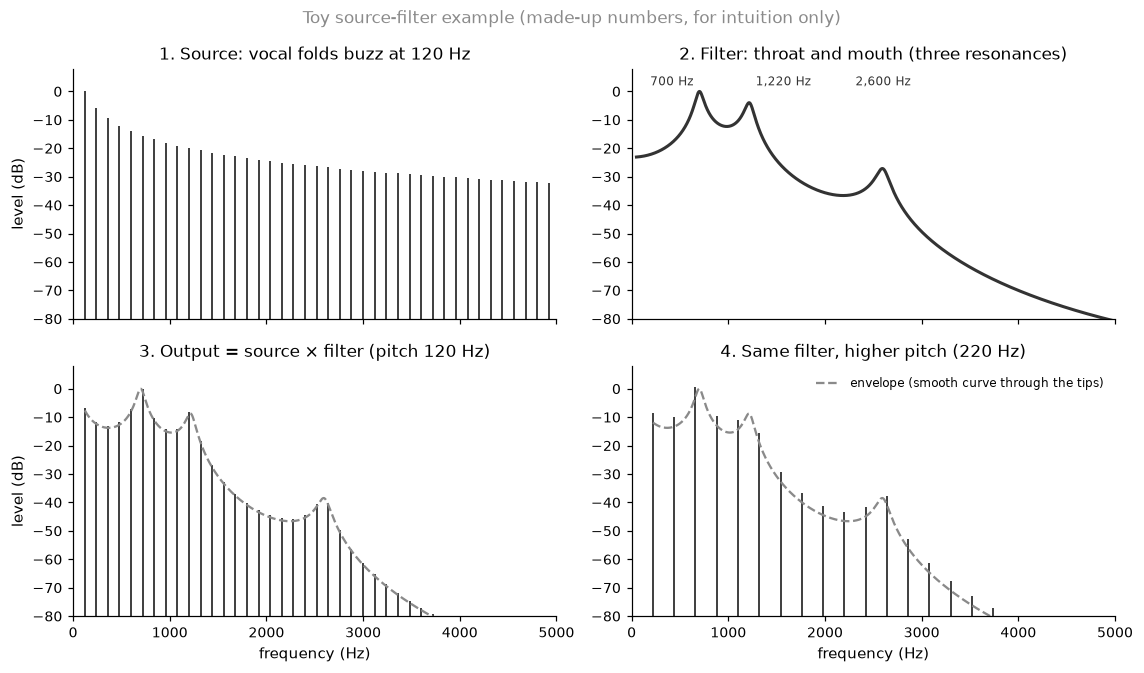

In [2]:
from scipy.signal import freqz

SR = 16_000
FORMANTS = [(700, 80), (1220, 90), (2600, 120)]   # (centre Hz, bandwidth Hz), toy values


def filter_db(freqs):
    # All-pole filter: one resonant pole pair per formant.
    a = np.array([1.0])
    for fc, bw in FORMANTS:
        r = np.exp(-np.pi * bw / SR)
        theta = 2 * np.pi * fc / SR
        a = np.convolve(a, [1.0, -2 * r * np.cos(theta), r * r])
    _, h = freqz([1.0], a, worN=freqs, fs=SR)
    db = 20 * np.log10(np.abs(h))
    return db - db.max()


def source_db(f0, fmax=5000):
    h = np.arange(f0, fmax, f0)
    return h, -6 * np.log2(h / f0)           # -6 dB per octave above the fundamental (toy)


grid = np.linspace(50, 5000, 2000)
env = filter_db(grid)

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.2), sharex=True)
(ax_s, ax_f), (ax_o1, ax_o2) = axes

h, s = source_db(120)
ax_s.vlines(h, -80, s, color=INK, lw=1.2)
ax_s.set_title("1. Source: vocal folds buzz at 120 Hz")
ax_s.set_ylabel("level (dB)")

ax_f.plot(grid, env, color=INK, lw=2)
for (fc, _), dx, ha in zip(FORMANTS, [-4, 4, 0], ["right", "left", "center"]):
    ax_f.annotate(f"{fc:,} Hz", (fc, filter_db(np.array([fc]))[0]), xytext=(dx, 4),
                  textcoords="offset points", ha=ha, fontsize=8, color=INK)
ax_f.set_title("2. Filter: throat and mouth (three resonances)")

for ax, f0 in [(ax_o1, 120), (ax_o2, 220)]:
    h, s = source_db(f0)
    out = s + filter_db(h)
    # Smooth curve through the tips: source tilt + filter, same normalisation as the tips.
    above = grid >= f0                       # the envelope only exists from the fundamental up
    smooth = -6 * np.log2(grid[above] / f0) + env[above]
    top = smooth.max()
    ax.vlines(h, -80, out - top, color=INK, lw=1.2)
    ax.plot(grid[above], smooth - top, color=MUTED, ls="--", lw=1.5,
            label="envelope (smooth curve through the tips)")
    ax.set_xlabel("frequency (Hz)")
ax_o1.set_title("3. Output = source × filter (pitch 120 Hz)")
ax_o1.set_ylabel("level (dB)")
ax_o2.set_title("4. Same filter, higher pitch (220 Hz)")
ax_o2.legend(loc="upper right", fontsize=8)

for ax in axes.flat:
    ax.set_ylim(-80, 8)
    ax.set_xlim(0, 5000)
fig.suptitle("Toy source-filter example (made-up numbers, for intuition only)", fontsize=11,
             color=MUTED)
fig.tight_layout()
save(fig, "ch01_source_filter_toy")
plt.show()

## Report figure (ch 02): how many clips, of which kind, in which split

**Source:** the local manifests `data/manifests/{train,dev,eval,itw}.csv` (gitignored; built by
`scripts/prepare_data.py`). The cell first checks them against the SHA-256 sums committed in
`data/manifests/SHA256SUMS`, and cross-checks the dev, eval and In-the-Wild totals against the
committed `metrics.json` files, so the counts are tied to committed evidence.

What to look at: in every ASVspoof panel the green bona fide bar is about the height of **one**
orange attack bar, but there are six or thirteen orange bars, so fakes outnumber real clips
about 9 to 1. The eval panel has a completely different set of attacks (A07–A19) from train
and dev (A01–A06). Hatched bars (A16, A19) reuse a training algorithm on new speakers.
In-the-Wild flips the balance: most clips are real, and its fakes carry no attack label.

In [3]:
from audio_df.data import manifests as audio_data

bad = audio_data.verify_checksums("data/manifests/SHA256SUMS", base_dir=REPO_ROOT)
assert not bad, bad
print("manifests match the committed SHA256SUMS")

man = {s: pd.read_csv(f"data/manifests/{s}.csv") for s in ["train", "dev", "eval", "itw"]}

# Cross-check totals against committed metrics.json files.
checks = {
    "dev": "runs/E-20261001-e1-a2-raw/metrics.json",
    "eval": "runs/E-20261001-e1-a2-raw/metrics.json",
    "itw": "runs/E-20261001-e3-a2-raw/metrics.json",
}
for split, path in checks.items():
    t = json.load(open(path))["testsets"][split]
    m = man[split]
    assert (t["n_bonafide"], t["n_spoof"]) == ((m.label == "bonafide").sum(), (m.label == "spoof").sum())
    print(f"{split:5s} bona fide {t['n_bonafide']:>6,}  spoof {t['n_spoof']:>6,}  (matches {path})")
tr = man["train"]
print(f"train bona fide {(tr.label == 'bonafide').sum():>6,}  spoof {(tr.label == 'spoof').sum():>6,}  (manifest only)")

counts = {}
for split in ["train", "dev", "eval"]:
    m = man[split]
    c = m.assign(group=np.where(m.label == "bonafide", "bona fide", m.attack_id)).group.value_counts()
    order = ["bona fide"] + sorted(k for k in c.index if k != "bona fide")
    counts[split] = c[order]
    print(split, c[order].to_dict())
itw = man["itw"].label.value_counts()
counts["itw"] = pd.Series({"bona fide": itw["bonafide"], "spoof\n(no label)": itw["spoof"]})

manifests match the committed SHA256SUMS


dev   bona fide  2,548  spoof 22,296  (matches runs/E-20261001-e1-a2-raw/metrics.json)
eval  bona fide  7,355  spoof 63,882  (matches runs/E-20261001-e1-a2-raw/metrics.json)
itw   bona fide 19,963  spoof 11,816  (matches runs/E-20261001-e3-a2-raw/metrics.json)
train bona fide  2,580  spoof 22,800  (manifest only)
train {'bona fide': 2580, 'A01': 3800, 'A02': 3800, 'A03': 3800, 'A04': 3800, 'A05': 3800, 'A06': 3800}
dev {'bona fide': 2548, 'A01': 3716, 'A02': 3716, 'A03': 3716, 'A04': 3716, 'A05': 3716, 'A06': 3716}
eval {'bona fide': 7355, 'A07': 4914, 'A08': 4914, 'A09': 4914, 'A10': 4914, 'A11': 4914, 'A12': 4914, 'A13': 4914, 'A14': 4914, 'A15': 4914, 'A16': 4914, 'A17': 4914, 'A18': 4914, 'A19': 4914}


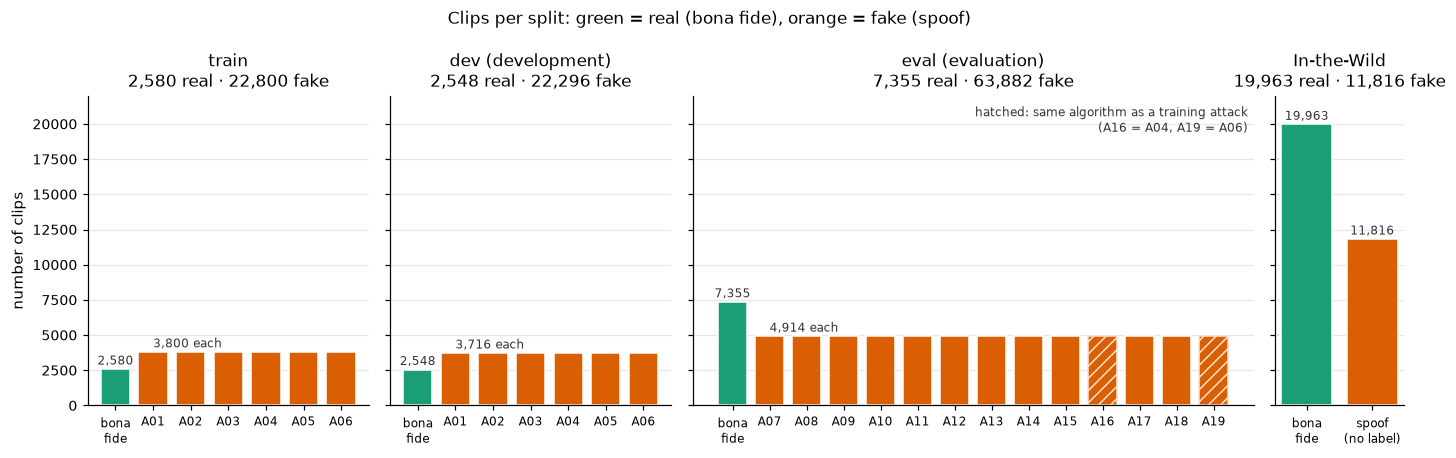

In [4]:
KNOWN_TWIN = {"A16": "A04", "A19": "A06"}
fig, axes = plt.subplots(1, 4, figsize=(13, 4.2), sharey=True,
                         gridspec_kw={"width_ratios": [7, 7, 14, 3.2]})
titles = {"train": "train", "dev": "dev (development)", "eval": "eval (evaluation)",
          "itw": "In-the-Wild"}
for ax, split in zip(axes, ["train", "dev", "eval", "itw"]):
    c = counts[split]
    x = np.arange(len(c))
    colors = [BONA if k == "bona fide" else SPOOF for k in c.index]
    hatches = ["///" if k in KNOWN_TWIN else "" for k in c.index]
    bars = ax.bar(x, c.values, color=colors, width=0.78, edgecolor="white", linewidth=1)
    for b, hch in zip(bars, hatches):
        if hch:
            b.set_hatch(hch)
            b.set_edgecolor("#fbe2cf")
    ax.set_xticks(x, [k.replace("bona fide", "bona\nfide") for k in c.index], rotation=0,
                  fontsize=8)
    # Direct labels: the bona fide bar and the first attack bar only.
    ax.annotate(f"{c.iloc[0]:,}", (0, c.iloc[0]), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=8, color=INK)
    if len(c) > 1:
        lab = f"{c.iloc[1]:,}" if split == "itw" else f"{c.iloc[1]:,} each"
        ax.annotate(lab, (1, c.iloc[1]), xytext=(0, 3), textcoords="offset points",
                    ha="left" if split != "itw" else "center", fontsize=8, color=INK)
    n_b = c.iloc[0]
    n_s = c.iloc[1:].sum()
    ax.set_title(f"{titles[split]}\n{n_b:,} real · {n_s:,} fake")
    ax.grid(axis="y", color="#e6e6e6", lw=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("number of clips")
axes[2].text(0.99, 0.97, "hatched: same algorithm as a training attack\n(A16 = A04, A19 = A06)",
             transform=axes[2].transAxes, ha="right", va="top", fontsize=8, color=INK)
axes[0].set_ylim(0, 22_000)
fig.suptitle("Clips per split: green = real (bona fide), orange = fake (spoof)", fontsize=11)
fig.tight_layout()
save(fig, "ch02_clips_per_split")
plt.show()

## Report figure (ch 02): sliding the threshold, misses against false alarms

**Source:** `runs/E-20261001-e1-a2-raw/scores/dev.csv` (committed): A2's score for every
one of the 24,844 dev clips, higher meaning "more real". The curves are recomputed from those
scores; cell 8 checks that the EER and its threshold match the committed `metrics.json`.

What to look at: (left) the two piles of scores, real on the right and fake on the left, with a
little overlap. (middle) slide a threshold from left to right. The green curve, real clips
wrongly rejected (misses), climbs; the orange curve, fake clips wrongly accepted (false alarms),
falls. (right) zoomed in: they cross at one threshold, and the error rate there is the **equal
error rate (EER)**.

In [5]:
from audio_df.evaluation.metrics import compute_eer

dev = pd.read_csv("runs/E-20261001-e1-a2-raw/scores/dev.csv")
b = np.sort(dev.loc[dev.label == "bonafide", "score"].to_numpy())
s = np.sort(dev.loc[dev.label == "spoof", "score"].to_numpy())
eer, thr = compute_eer(dev.score, dev.label, higher_is_spoof=False)
stored = json.load(open("runs/E-20261001-e1-a2-raw/metrics.json"))["testsets"]["dev"]
assert np.isclose(eer, stored["eer"]) and np.isclose(thr, stored["eer_threshold"])
print(f"dev clips: {len(b):,} real, {len(s):,} fake")
print(f"EER = {eer:.4%} at threshold {thr:.3f} (matches metrics.json)")
print(f"median score: real {np.median(b):+.2f}, fake {np.median(s):+.2f}")
always_fake_acc = len(s) / (len(s) + len(b))
print(f"accuracy of a rule that always says 'fake': {always_fake_acc:.1%}")

theta = np.linspace(-40, 30, 3000)
p_miss = np.searchsorted(b, theta, side="right") / len(b)      # real scored <= theta
p_fa = 1 - np.searchsorted(s, theta, side="right") / len(s)    # fake scored  > theta

dev clips: 2,548 real, 22,296 fake
EER = 0.3936% at threshold -2.425 (matches metrics.json)
median score: real +13.09, fake -16.87
accuracy of a rule that always says 'fake': 89.7%


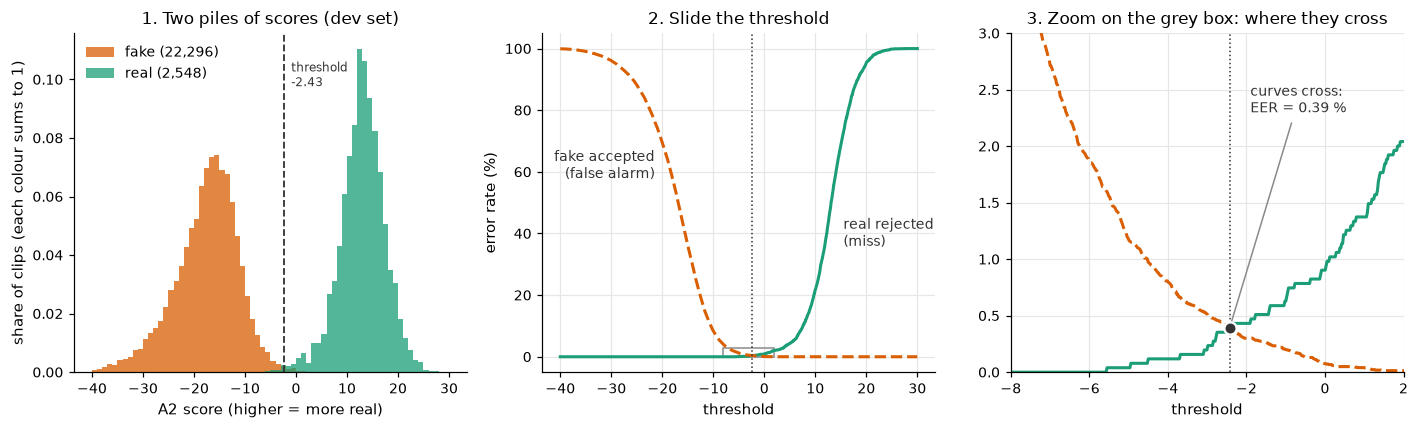

In [6]:
fig, (ax_h, ax_c, ax_z) = plt.subplots(1, 3, figsize=(13, 4))
bins = np.linspace(-40, 30, 71)
ax_h.hist(s, bins=bins, density=True, color=SPOOF, alpha=0.75, label=f"fake ({len(s):,})")
ax_h.hist(b, bins=bins, density=True, color=BONA, alpha=0.75, label=f"real ({len(b):,})")
ax_h.axvline(thr, color=INK, lw=1.2, ls="--")
ax_h.annotate(f"threshold\n{thr:.2f}", (thr, ax_h.get_ylim()[1] * 0.92), xytext=(5, 0),
              textcoords="offset points", fontsize=8, color=INK, va="top")
ax_h.set_xlabel("A2 score (higher = more real)")
ax_h.set_ylabel("share of clips (each colour sums to 1)")
ax_h.set_title("1. Two piles of scores (dev set)")
ax_h.legend(loc="upper left")

for ax in (ax_c, ax_z):
    ax.plot(theta, 100 * p_miss, color=BONA, lw=2, label="real rejected (miss)")
    ax.plot(theta, 100 * p_fa, color=SPOOF, lw=2, ls="--", label="fake accepted (false alarm)")
    ax.axvline(thr, color=INK, lw=1, ls=":")
    ax.set_xlabel("threshold")
    ax.grid(color="#e6e6e6", lw=0.8)
    ax.set_axisbelow(True)
ax_c.set_ylabel("error rate (%)")
ax_c.set_title("2. Slide the threshold")
# Direct labels instead of a legend box (each sits beside its own curve).
ax_c.text(-21.5, 62, "fake accepted\n(false alarm)", ha="right", va="center", fontsize=9, color=INK)
ax_c.text(15.5, 40, "real rejected\n(miss)", ha="left", va="center", fontsize=9, color=INK)
ax_c.add_patch(plt.Rectangle((-8, 0), 10, 3, fill=False, ec=MUTED, lw=1))

ax_z.set_xlim(-8, 2)
ax_z.set_ylim(0, 3)
ax_z.plot([thr], [100 * eer], "o", ms=8, color=INK, mec="white", mew=1.5, zorder=5)
ax_z.annotate(f"curves cross:\nEER = {100 * eer:.2f} %", (thr, 100 * eer), xytext=(-1.9, 2.3),
              textcoords="data", fontsize=9, color=INK,
              arrowprops=dict(arrowstyle="-", color=MUTED))
ax_z.set_title("3. Zoom on the grey box: where they cross")
fig.tight_layout()
save(fig, "ch02_threshold_sweep")
plt.show()

## Report figure (ch 03): how much silence each clip starts with

**Source:** `data/metadata/nuisance_features.csv`: the per-clip output of
`leakage.extract_nuisance_features` for all 121,461 clips, saved locally (not in git; no
committed script writes it to that path; to regenerate it, run notebook 01 cell 14 and save the
frame). Nothing is recomputed from audio here.

What to look at: (left) many fakes start with almost no silence (orange spike at 0), real clips
with about a third of the clip silent; a low orange hump under the green one is the fakes that
start like real clips. (right) the median per attack: the hatched attacks, which convert a real
person's recording (ASVspoof 2019 database paper, Table 1), sit level with real speech, as does text-to-speech attack A02.

median leading-silence fraction: real 0.309, fake 0.040
share of clips with < 1 % leading silence: real 0.2%, fake 29.5%
{'A01': 0.037, 'A02': 0.285, 'A03': 0.121, 'A04': 0.011, 'A05': 0.31, 'A06': 0.294, 'A07': 0.005, 'A08': 0.07, 'A09': 0.013, 'A10': 0.0, 'A11': 0.0, 'A12': 0.0, 'A13': 0.0, 'A14': 0.009, 'A15': 0.009, 'A16': 0.012, 'A17': 0.303, 'A18': 0.31, 'A19': 0.289}


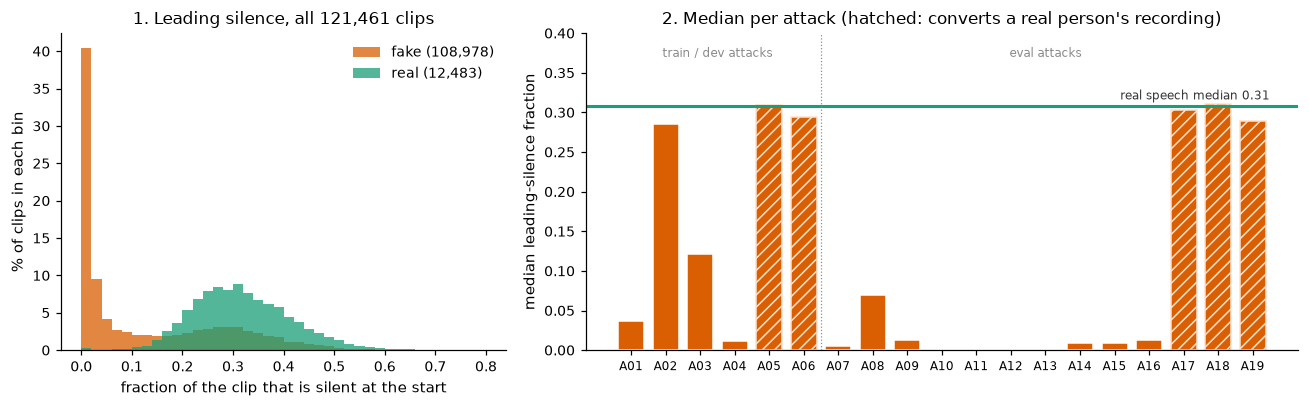

In [7]:
nf = pd.read_csv("data/metadata/nuisance_features.csv")
assert len(nf) == 121_461
lead_b = nf.loc[nf.label == "bonafide", "silence_leading"]
lead_s = nf.loc[nf.label == "spoof", "silence_leading"]
print(f"median leading-silence fraction: real {lead_b.median():.3f}, fake {lead_s.median():.3f}")
print(f"share of clips with < 1 % leading silence: real {(lead_b < 0.01).mean():.1%}, "
      f"fake {(lead_s < 0.01).mean():.1%}")
med = nf[nf.label == "spoof"].groupby("attack_id").silence_leading.median()
print(med.round(3).to_dict())

fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
bins = np.linspace(0, 0.8, 41)
ax_l.hist(lead_s, bins=bins, weights=np.full(len(lead_s), 100 / len(lead_s)), color=SPOOF,
          alpha=0.75, label=f"fake ({len(lead_s):,})")
ax_l.hist(lead_b, bins=bins, weights=np.full(len(lead_b), 100 / len(lead_b)), color=BONA,
          alpha=0.75, label=f"real ({len(lead_b):,})")
ax_l.set_xlabel("fraction of the clip that is silent at the start")
ax_l.set_ylabel("% of clips in each bin")
ax_l.set_title("1. Leading silence, all 121,461 clips")
ax_l.legend()

x = np.arange(len(med))
human = {"A17", "A18", "A19", "A05", "A06"}
ax_r.bar(x, med.values, color=SPOOF, width=0.75, edgecolor="white")
for i, a in enumerate(med.index):
    if a in human:
        ax_r.patches[i].set_hatch("///")
        ax_r.patches[i].set_edgecolor("#fbe2cf")
ax_r.axhline(lead_b.median(), color=BONA, lw=2)
ax_r.annotate(f"real speech median {lead_b.median():.2f}", (len(med) - 0.5, lead_b.median()),
              xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8, color=INK)
ax_r.set_xticks(x, med.index, fontsize=8)
ax_r.axvline(5.5, color=MUTED, lw=0.8, ls=":")
ax_r.text(2.5, 0.37, "train / dev attacks", ha="center", fontsize=8, color=MUTED)
ax_r.text(12, 0.37, "eval attacks", ha="center", fontsize=8, color=MUTED)
ax_r.set_ylim(0, 0.4)
ax_r.set_ylabel("median leading-silence fraction")
ax_r.set_title("2. Median per attack (hatched: converts a real person's recording)")
fig.tight_layout()
save(fig, "ch03_leading_silence")
plt.show()

## Report figure (ch 05): where the 20 filters sit, linear against mel

**Source:** the project's own filterbank function
[`lfcc_b02_filterbank`](../src/audio_df/features/lfcc_b02.py) (the A1 front end), called with
`spacing="linear"` (LFCC) and `spacing="mel"` (MFCC, the arm of the E2 front-end comparison). No audio, no data: this is
pure geometry, computed here.

What to look at: both rows have 20 triangles between 0 and 8,000 Hz. The linear row (blue)
spaces them evenly, so half of them sit above 4 kHz. The mel row (magenta) crowds them into
the low frequencies and stretches the top ones wide. The printed table counts them.
Blue = linear/LFCC and magenta = mel/MFCC in every figure from here on.

spacing                      linear   mel
centred > 4 kHz                  10     5
centred > 6 kHz                   5     2
centred < 1 kHz                   2     7
lowest width (Hz)               762   190
top width (Hz)                  762  1856
mean width above 4 kHz (Hz)     762  1481


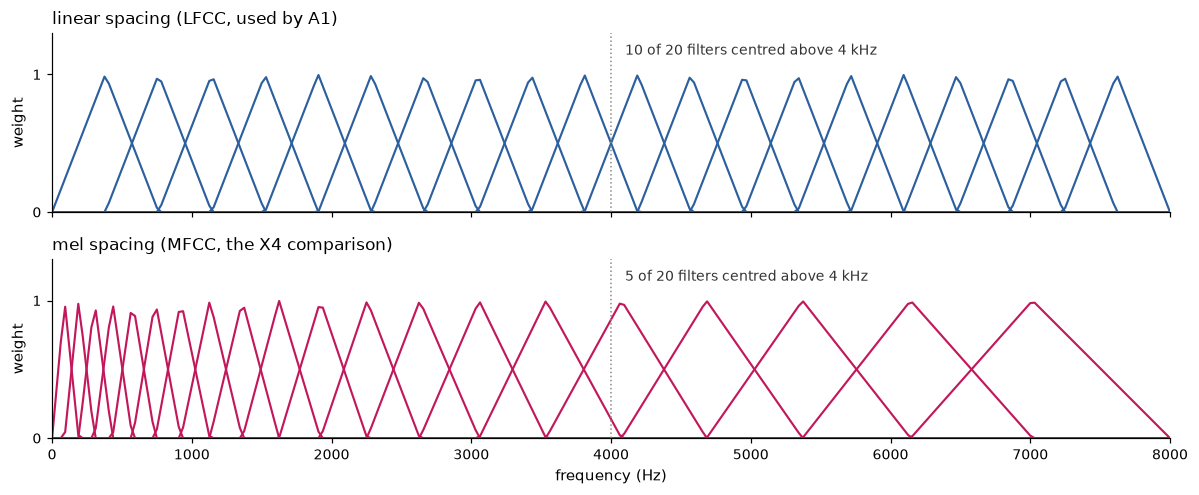

In [8]:
from audio_df.features.lfcc_b02 import lfcc_b02_filterbank

LIN, MEL = "#2c5f9e", "#c2185b"   # linear/LFCC = blue, mel/MFCC = magenta (validated pair)
SR_A1, NFFT = 16_000, 512
f_bins = np.linspace(0, SR_A1 / 2, NFFT // 2 + 1)


def edges(spacing):
    from audio_df.features.cepstral import hz_to_mel, mel_to_hz
    if spacing == "linear":
        return np.linspace(0, 8000, 22)
    return np.asarray(mel_to_hz(np.linspace(hz_to_mel(0.0), hz_to_mel(8000.0), 22)))


rows = []
for spacing in ["linear", "mel"]:
    e = edges(spacing)
    centres, widths = e[1:-1], e[2:] - e[:-2]
    psi = lfcc_b02_filterbank(20, NFFT, SR_A1, spacing=spacing)
    assert np.allclose(f_bins[psi.argmax(axis=1)], centres, atol=f_bins[1])  # same edges as the code
    hi = centres > 4000
    rows.append({
        "spacing": spacing,
        "centred > 4 kHz": int(hi.sum()),
        "centred > 6 kHz": int((centres > 6000).sum()),
        "centred < 1 kHz": int((centres < 1000).sum()),
        "lowest width (Hz)": round(widths[0]),
        "top width (Hz)": round(widths[-1]),
        "mean width above 4 kHz (Hz)": round(widths[hi].mean()),
    })
print(pd.DataFrame(rows).set_index("spacing").T.to_string())

fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True)
for ax, spacing, col, name in [(axes[0], "linear", LIN, "linear spacing (LFCC, used by A1)"),
                               (axes[1], "mel", MEL, "mel spacing (MFCC, the X4 comparison)")]:
    psi = lfcc_b02_filterbank(20, NFFT, SR_A1, spacing=spacing)
    for r in psi:
        ax.plot(f_bins, r, color=col, lw=1.4)
    ax.axvline(4000, color=MUTED, ls=":", lw=1)
    n_hi = int((edges(spacing)[1:-1] > 4000).sum())
    ax.text(4100, 1.12, f"{n_hi} of 20 filters centred above 4 kHz", fontsize=9, color=INK, va="bottom")
    ax.set_ylim(0, 1.3)
    ax.set_title(name, loc="left")
    ax.set_yticks([0, 1])
    ax.set_ylabel("weight")
axes[1].set_xlabel("frequency (Hz)")
axes[1].set_xlim(0, 8000)
fig.tight_layout()
save(fig, "ch05_filter_placement")
plt.show()

## Report figure (ch 05): what each LFCC number measures, and a gain change on one clip

**Left: no data.** The weights the discrete cosine transform (DCT) gives to the 20 filter
outputs for a few coefficients (orthonormal DCT-II, as A1 uses). c0 weighs every filter
equally (overall level), c1 goes from + on low filters to − on high ones (tilt), and higher
coefficients wiggle faster (ripple).

**Middle and right: recomputed** on one real bona fide eval clip (the first
bona fide row of `data/manifests/eval.csv`), using the A1 front end
[`extract_lfcc_b02`](../src/audio_df/features/lfcc_b02.py). The same clip is processed twice: as
recorded, and turned down by 10 dB (amplitude × 0.316). Only c0 moves, by the same amount in
every frame (−4.47 = −√20); the other 19 coefficients do not change.

clip LA_E_5849185: 439 frames
mean change of c0: -4.472  (theory: -sqrt(20) = -4.472)
largest change of any c1..c19 in any frame: 8.94e-06


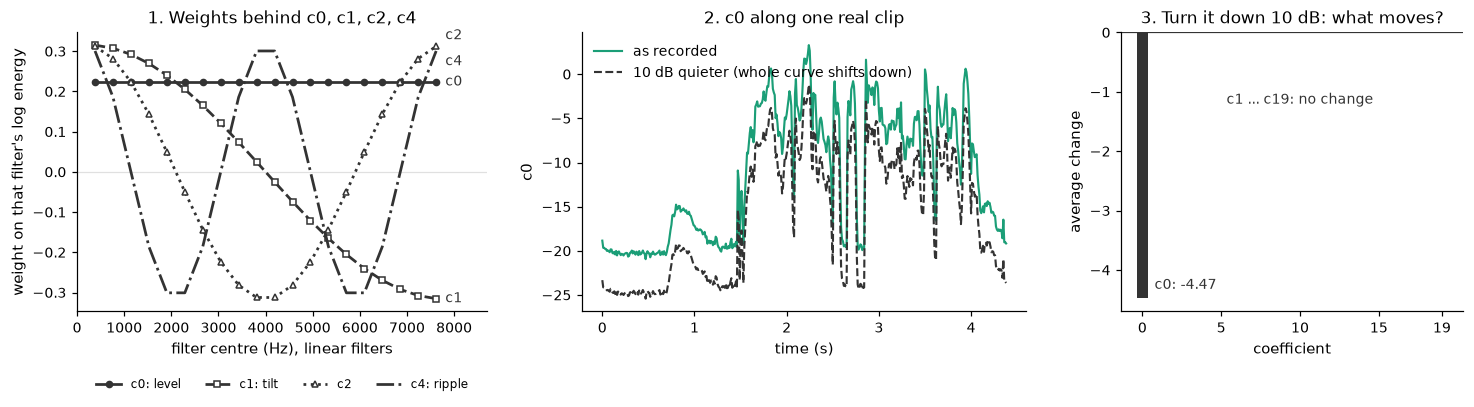

In [9]:
from scipy.fft import dct as _dct

from audio_df.features.audio import load_audio
from audio_df.features.lfcc_b02 import extract_lfcc_b02

J = 20
basis = _dct(np.eye(J), type=2, norm="ortho", axis=0)   # row q = weights of coefficient c_q
lin_centres = np.linspace(0, 8000, 22)[1:-1]

ev_man = pd.read_csv("data/manifests/eval.csv")
clip = ev_man[ev_man.label == "bonafide"].iloc[0]
x, _ = load_audio(clip.path, target_sr=16_000)
gain = 10 ** (-10 / 20)                                  # -10 dB
c_orig = extract_lfcc_b02(x, 16_000)[:, :J]
c_quiet = extract_lfcc_b02(x * gain, 16_000)[:, :J]
shift = (c_quiet - c_orig).mean(axis=0)
print(f"clip {clip.utt_id}: {len(c_orig)} frames")
print(f"mean change of c0: {shift[0]:+.3f}  (theory: -sqrt(20) = {-np.sqrt(20):+.3f})")
print(f"largest change of any c1..c19 in any frame: {np.abs(c_quiet - c_orig)[:, 1:].max():.2e}")

fig, (ax_b, ax_t, ax_s) = plt.subplots(1, 3, figsize=(13.5, 3.9),
                                       gridspec_kw={"width_ratios": [1.2, 1.3, 1]})
for q, ls, mk, lab in [(0, "-", "o", "c0: level"), (1, "--", "s", "c1: tilt"),
                       (2, ":", "^", "c2"), (4, "-.", None, "c4: ripple")]:
    ax_b.plot(lin_centres, basis[q], ls=ls, lw=1.8, color=INK, marker=mk, ms=4,
              mfc="white" if mk in ("s", "^") else INK, label=lab)
    ax_b.annotate(lab.split(":")[0], (lin_centres[-1], basis[q][-1]),
                  xytext=(6, {2: 7, 4: -7}.get(q, 0)),
                  textcoords="offset points", fontsize=9, color=INK, va="center")
ax_b.set_xlim(0, 8700)
ax_b.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=8)
ax_b.axhline(0, color="#e0e0e0", lw=0.8, zorder=0)
ax_b.set_xlabel("filter centre (Hz), linear filters")
ax_b.set_ylabel("weight on that filter's log energy")
ax_b.set_title("1. Weights behind c0, c1, c2, c4")

t = np.arange(len(c_orig)) / 100
ax_t.plot(t, c_orig[:, 0], color=BONA, lw=1.4, label="as recorded")
ax_t.plot(t, c_quiet[:, 0], color=INK, lw=1.4, ls="--", label="10 dB quieter (whole curve shifts down)")
ax_t.set_xlabel("time (s)")
ax_t.set_ylabel("c0")
ax_t.set_title("2. c0 along one real clip")
ax_t.legend(loc="upper left")

ax_s.bar(np.arange(J), shift, color=[INK] + ["#9a9a9a"] * (J - 1), width=0.7)
ax_s.axhline(0, color=INK, lw=0.8)
ax_s.annotate(f"c0: {shift[0]:.2f}", (0, shift[0]), xytext=(8, 6), textcoords="offset points",
              fontsize=9, color=INK)
ax_s.text(10, -1.2, "c1 ... c19: no change", ha="center", fontsize=9, color=INK)
ax_s.set_xticks([0, 5, 10, 15, 19])
ax_s.set_xlabel("coefficient")
ax_s.set_ylabel("average change")
ax_s.set_title("3. Turn it down 10 dB: what moves?")
fig.tight_layout()
save(fig, "ch05_lfcc_coefficients_gain")
plt.show()

## Report figure (ch 05): why the DCT step is there (redraw of notebook 03's correlation figure)

**Recomputed here.** Notebook 03 draws the same correlation comparison. This cell
rebuilds notebook 03's exact sample (15 clips per split and class, seed 1, 45 bona fide clips)
from the local manifests and redraws it in the report's style. It reproduces notebook 03's
printed numbers (0.851 and 0.166).

What to look at: on the left, the 20 log filter energies (before the DCT) are almost all
strongly correlated with each other: one big red block. On the right, after the DCT, the
off-diagonal is mostly pale. A model that assumes its inputs are uncorrelated (a diagonal
Gaussian, chapter 6) is a poor fit to the left and a fair fit to the right.

feat_a_linear_logfb: 45 bona fide clips, mean |off-diagonal correlation| = 0.851
feat_b_lfcc_full: 45 bona fide clips, mean |off-diagonal correlation| = 0.166


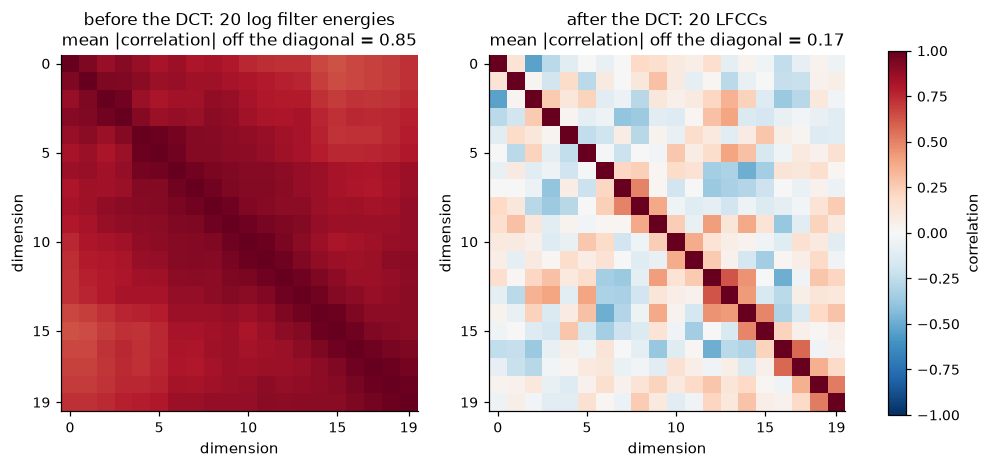

In [10]:
import yaml

from audio_df.features import audio as _audio
from audio_df.features import cepstral as _features

FEAT = yaml.safe_load(open("configs/features.yaml"))
FEAT.setdefault("sr", 16000)
man3 = pd.concat([pd.read_csv(f"data/manifests/{s}.csv") for s in ["train", "dev", "eval"]],
                 ignore_index=True)
_rng = np.random.default_rng(1)
parts = []
for _, g in man3.groupby(["split", "label"], dropna=False):
    parts.append(man3.loc[_rng.choice(g.index.to_numpy(), size=min(15, len(g)), replace=False)])
eda3 = pd.concat(parts).reset_index(drop=True)
bona3 = eda3[eda3.label == "bonafide"]

corr = {}
for v in ["feat_a_linear_logfb", "feat_b_lfcc_full"]:
    M = np.stack([_features.extract(_audio.load_audio(p, target_sr=16000)[0], v, FEAT).mean(0)
                  for p in bona3.path])
    corr[v] = np.corrcoef(M.T)
    off = np.abs(corr[v][~np.eye(20, dtype=bool)]).mean()
    print(f"{v}: {len(bona3)} bona fide clips, mean |off-diagonal correlation| = {off:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
titles = {"feat_a_linear_logfb": "before the DCT: 20 log filter energies",
          "feat_b_lfcc_full": "after the DCT: 20 LFCCs"}
for ax, (v, c) in zip(axes, corr.items()):
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    off = np.abs(c[~np.eye(20, dtype=bool)]).mean()
    ax.set_title(f"{titles[v]}\nmean |correlation| off the diagonal = {off:.2f}")
    ax.set_xticks([0, 5, 10, 15, 19])
    ax.set_yticks([0, 5, 10, 15, 19])
    ax.set_xlabel("dimension")
    ax.set_ylabel("dimension")
fig.colorbar(im, ax=axes, fraction=0.03, label="correlation")
save(fig, "ch05_dct_decorrelation")
plt.show()

## Report figure (ch 06): a Gaussian mixture model in two dimensions (toy)

**Toy example, made-up data.** Two clouds of 2-D points stand in for "real frames" and "fake
frames". Each cloud gets its own Gaussian mixture model (GMM) with 3 components, fitted with
the project's own [`DiagGMM.fit_em`](../src/audio_df/models/gmm.py) (expectation-maximisation,
10 iterations), the same code A1 uses with 512 components in 60 dimensions.

What to look at: (left) each model's ellipses hug its own cloud. (right) the colour is the
log-likelihood ratio, log p(point | real model) − log p(point | fake model): green where the
real model explains a point better, orange where the fake model does. A1 scores a clip by
averaging this number over all its frames.

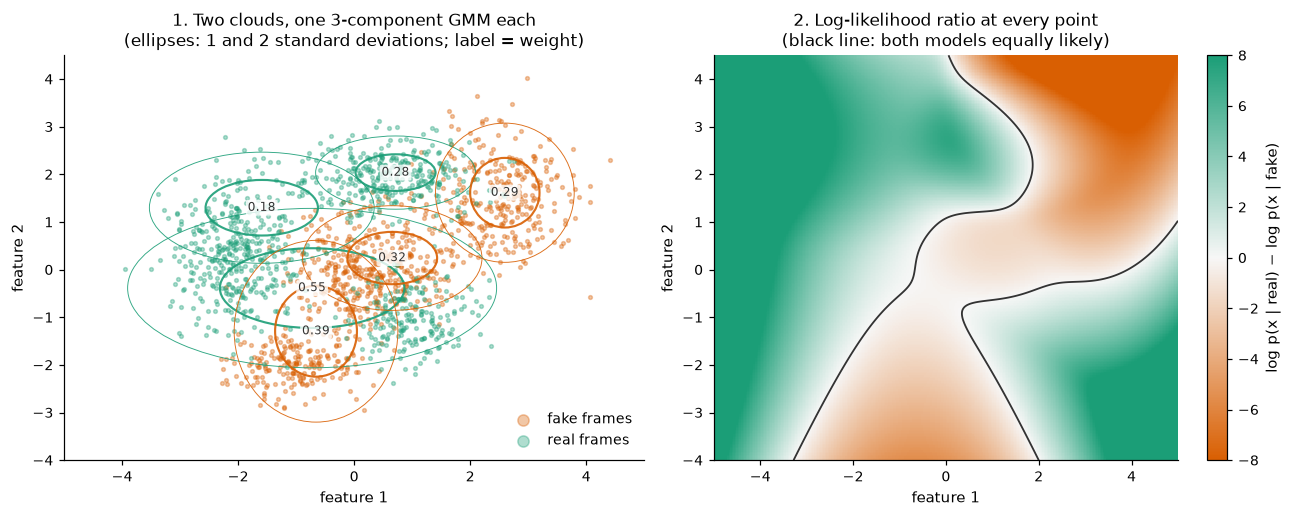

In [11]:
from audio_df.models.gmm import DiagGMM

_r = np.random.default_rng(7)
real_pts = np.concatenate([_r.normal([-2.0, 0.5], [0.6, 0.9], (400, 2)),
                           _r.normal([0.5, 2.0], [0.8, 0.4], (300, 2)),
                           _r.normal([1.0, -1.0], [0.5, 0.5], (200, 2))])
fake_pts = np.concatenate([_r.normal([0.2, 0.0], [0.7, 0.6], (400, 2)),
                           _r.normal([2.5, 1.5], [0.6, 0.8], (300, 2)),
                           _r.normal([-1.0, -2.0], [0.6, 0.4], (200, 2))])
g_real, g_fake = DiagGMM(3, 2), DiagGMM(3, 2)
g_real.fit_em(real_pts, n_iter=10, seed=0)
g_fake.fit_em(fake_pts, n_iter=10, seed=0)

xx, yy = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-4, 4.5, 260))
grid = np.c_[xx.ravel(), yy.ravel()]
llr_map = (g_real.score_log_likelihood(grid) - g_fake.score_log_likelihood(grid)).reshape(xx.shape)


def ellipses(ax, g, color):
    from matplotlib.patches import Ellipse
    for m, v, w in zip(g.means, g.vars_, g.weights):
        for k in (1, 2):
            ax.add_patch(Ellipse(m, 2 * k * np.sqrt(v[0]), 2 * k * np.sqrt(v[1]), fill=False,
                                 ec=color, lw=2.2 - 0.8 * k, alpha=0.9))
        ax.annotate(f"{w:.2f}", m, ha="center", va="center", fontsize=8, color=INK,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))


from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap_llr = LinearSegmentedColormap.from_list("llr", [SPOOF, "#f7f7f7", BONA])

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12, 4.8))
ax_a.scatter(*fake_pts.T, s=6, color=SPOOF, alpha=0.35, label="fake frames")
ax_a.scatter(*real_pts.T, s=6, color=BONA, alpha=0.35, label="real frames")
ellipses(ax_a, g_real, BONA)
ellipses(ax_a, g_fake, SPOOF)
ax_a.set_title("1. Two clouds, one 3-component GMM each\n(ellipses: 1 and 2 standard deviations; label = weight)")
ax_a.legend(loc="lower right", markerscale=3)

im = ax_b.pcolormesh(xx, yy, np.clip(llr_map, -8, 8), cmap=cmap_llr,
                     norm=TwoSlopeNorm(0, -8, 8), shading="auto")
ax_b.contour(xx, yy, llr_map, levels=[0], colors=INK, linewidths=1.2)
fig.colorbar(im, ax=ax_b, label="log p(x | real) − log p(x | fake)")
ax_b.set_title("2. Log-likelihood ratio at every point\n(black line: both models equally likely)")
for ax in (ax_a, ax_b):
    ax.set_xlim(-5, 5)
    ax.set_ylim(-4, 4.5)
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
fig.tight_layout()
save(fig, "ch06_gmm_toy")
plt.show()

## Report figure (ch 06): A1's score, frame by frame, on three real eval clips

**Source:** A1's two trained GMMs, `runs/E-20261001-e1-a1-raw/bona_gmm.npz` and
`spoof_gmm.npz` (**local files, not in git**), applied to three eval clips through the A1
front end. The per-frame values are recomputed here; the cell asserts that their mean
equals each clip's committed score in `runs/E-20261001-e1-a1-raw/scores/eval.csv`.

The three clips: one real clip, one A10 clip (WaveRNN vocoder) and one A11 clip (Griffin-Lim
vocoder). A10 and A11 are the same text-to-speech system except for the vocoder.

What to look at: each grey tick is one 10 ms frame's log-likelihood ratio; the thick line is
the clip's average, which is A1's score. The dashed line is A1's decision threshold from dev.
Shaded frames are the quietest fifth of each clip (lowest c0). The A10 clip's frames sit mostly
above zero, like the real clip's; the A11 clip's sit mostly below.

A1 dev threshold: 0.687
real (bona fide)             score +1.734 (committed +1.734), share of frames > 0: 75%
A10 (WaveRNN vocoder)        score +0.803 (committed +0.803), share of frames > 0: 65%


A11 (Griffin-Lim vocoder)    score -1.467 (committed -1.467), share of frames > 0: 35%


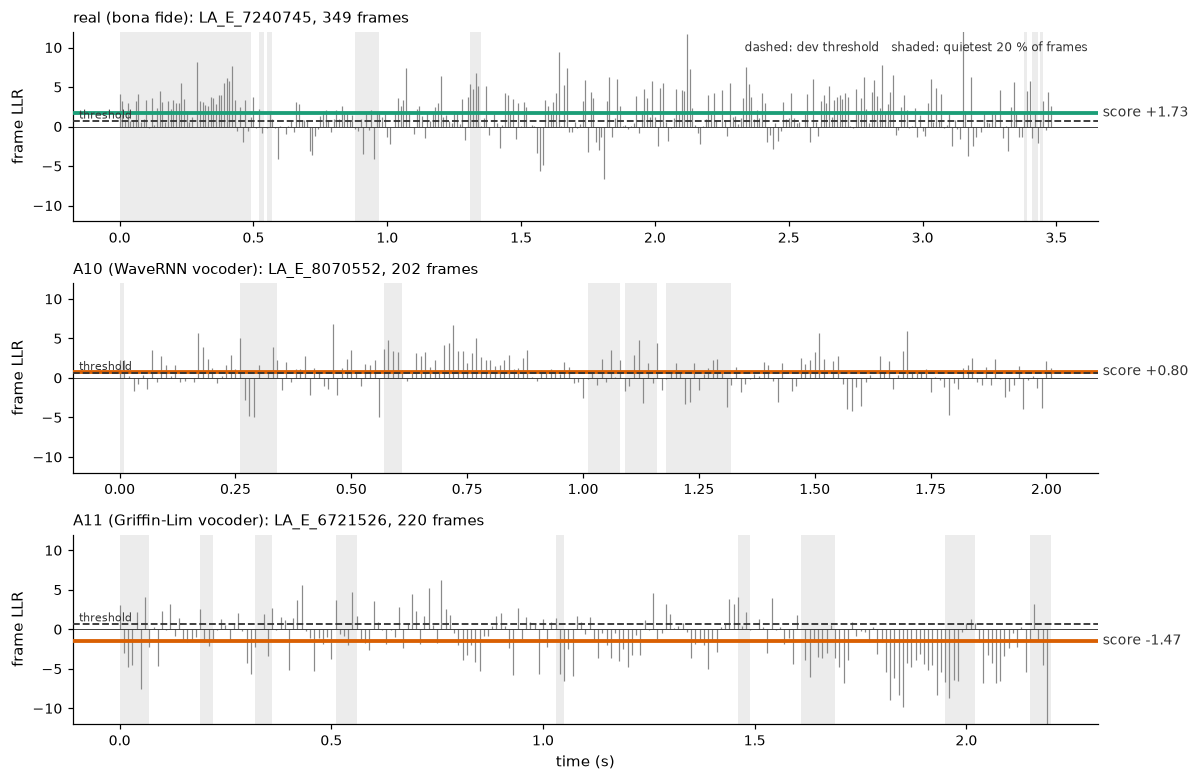

In [12]:
from audio_df.training.gmm import frames_for_row as extract_frames_for_row

A1_DIR = "runs/E-20261001-e1-a1-raw"
a1_cfg = yaml.safe_load(open(f"{A1_DIR}/config.yaml"))
g_bona = DiagGMM.load(f"{A1_DIR}/bona_gmm.npz")
g_spoof = DiagGMM.load(f"{A1_DIR}/spoof_gmm.npz")
a1_eval = pd.read_csv(f"{A1_DIR}/scores/eval.csv").set_index("clip_id")
a1_thr = json.load(open(f"{A1_DIR}/metrics.json"))["threshold_source"]["value"]
print(f"A1 dev threshold: {a1_thr:.3f}")

chosen = [("LA_E_7240745", "real (bona fide)", BONA),
          ("LA_E_8070552", "A10 (WaveRNN vocoder)", SPOOF),
          ("LA_E_6721526", "A11 (Griffin-Lim vocoder)", SPOOF)]
fig, axes = plt.subplots(3, 1, figsize=(11, 7.2), sharey=True)
for ax, (cid, name, col) in zip(axes, chosen):
    row = ev_man[ev_man.utt_id == cid].iloc[0]
    fr = extract_frames_for_row(row, a1_cfg)
    llr = g_bona.score_log_likelihood(fr) - g_spoof.score_log_likelihood(fr)
    assert np.isclose(llr.mean(), a1_eval.loc[cid, "score"]), cid
    t = np.arange(len(llr)) / 100
    quiet = fr[:, 0] < np.percentile(fr[:, 0], 20)
    for s0 in t[quiet]:
        ax.axvspan(s0, s0 + 0.01, color="#ececec", lw=0, zorder=0)
    ax.vlines(t, 0, llr, color="#8a8a8a", lw=0.8, zorder=1)
    ax.axhline(0, color=INK, lw=0.6)
    ax.axhline(llr.mean(), color=col, lw=2.5, zorder=3)
    ax.axhline(a1_thr, color=INK, lw=1.2, ls="--", zorder=4)
    ax.text(0.002, a1_thr, " threshold", transform=ax.get_yaxis_transform(), fontsize=7,
            color=INK, va="bottom", zorder=5)
    ax.text(1.005, llr.mean(), f"score {llr.mean():+.2f}", transform=ax.get_yaxis_transform(),
            fontsize=9, color=INK, va="center")
    ax.set_title(f"{name}: {cid}, {len(llr)} frames", loc="left", fontsize=10)
    ax.set_ylim(-12, 12)
    ax.set_ylabel("frame LLR")
    print(f"{name:28s} score {llr.mean():+.3f} (committed {a1_eval.loc[cid, 'score']:+.3f}), "
          f"share of frames > 0: {(llr > 0).mean():.0%}")
axes[-1].set_xlabel("time (s)")
axes[0].text(0.99, 0.95, "dashed: dev threshold   shaded: quietest 20 % of frames",
             transform=axes[0].transAxes, ha="right", va="top", fontsize=8, color=INK)
fig.tight_layout()
save(fig, "ch06_frame_llr")
plt.show()

## Report figure (ch 06): A1's scores on the whole eval set, and the A10 / A11 pair

**Source:** `runs/E-20261001-e1-a1-raw/scores/eval.csv` (committed) and the dev
threshold stored in that run's `metrics.json`. Notebook 10 draws a score histogram only once its
`exp_id` is set to a finished run; this cell draws it directly from the registered E1 run.

What to look at: (left) real clips (green) score mostly above the dashed dev threshold, fakes
(orange) mostly below, with a visible overlap. Scores below −6
(a few attacks, mostly A09) fall off the left edge. (right) the same real clips against just A10
and just A11. A11's scores sit far to the left; A10's overlap the real clips heavily.

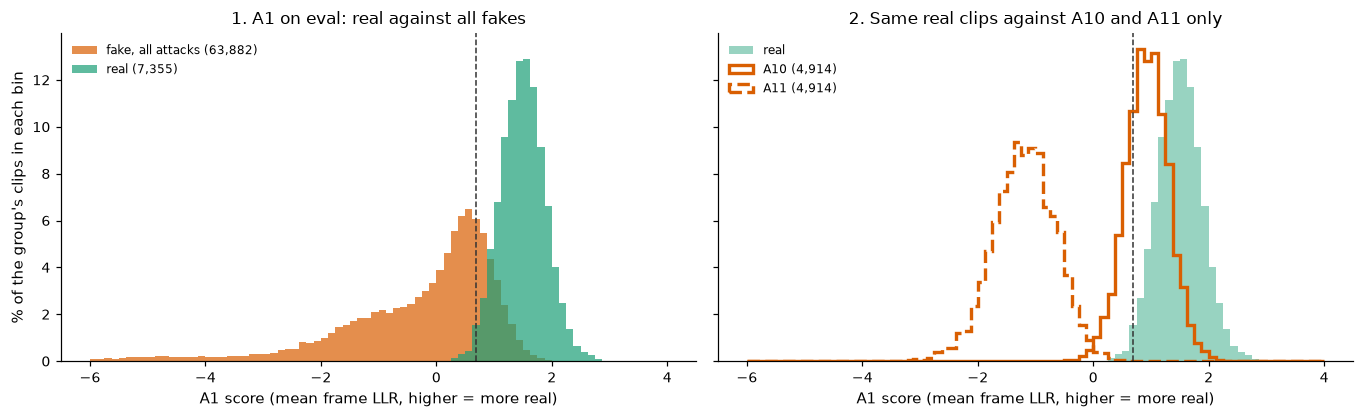

A10: median score +0.93, share above the dev threshold 74.5%
A11: median score -1.19, share above the dev threshold 0.0%
real: median score +1.50


In [13]:
a1e = a1_eval.reset_index()
bins = np.linspace(-6, 4, 81)
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
pct = lambda v: np.full(len(v), 100 / len(v))
ax_l.hist(a1e[a1e.label == "spoof"].score, bins=bins, weights=pct(a1e[a1e.label == "spoof"]), color=SPOOF, alpha=0.7,
          label=f"fake, all attacks ({(a1e.label == 'spoof').sum():,})")
ax_l.hist(a1e[a1e.label == "bonafide"].score, bins=bins, weights=pct(a1e[a1e.label == "bonafide"]), color=BONA, alpha=0.7,
          label=f"real ({(a1e.label == 'bonafide').sum():,})")
ax_r.hist(a1e[a1e.label == "bonafide"].score, bins=bins, weights=pct(a1e[a1e.label == "bonafide"]), color=BONA, alpha=0.45,
          label="real")
for att, ls, lw in [("A10", "-", 2.2), ("A11", "--", 2.2)]:
    ax_r.hist(a1e[a1e.attack_id == att].score, bins=bins, weights=pct(a1e[a1e.attack_id == att]), histtype="step",
              color=SPOOF, ls=ls, lw=lw, label=f"{att} ({(a1e.attack_id == att).sum():,})")
for ax in (ax_l, ax_r):
    ax.axvline(a1_thr, color=INK, ls="--", lw=1)
    ax.set_xlabel("A1 score (mean frame LLR, higher = more real)")
    ax.legend(loc="upper left", fontsize=8)
ax_l.set_ylabel("% of the group's clips in each bin")
ax_l.set_title("1. A1 on eval: real against all fakes")
ax_r.set_title("2. Same real clips against A10 and A11 only")
fig.tight_layout()
save(fig, "ch06_a1_eval_scores_a10_a11")
plt.show()
for att in ["A10", "A11"]:
    s = a1e[a1e.attack_id == att].score
    print(f"{att}: median score {s.median():+.2f}, share above the dev threshold {(s > a1_thr).mean():.1%}")
print(f"real: median score {a1e[a1e.label == 'bonafide'].score.median():+.2f}")

## Report figure (ch 06): LFCC against MFCC, attack by attack (E2 front-end runs, 3 seeds each)

**Source:** committed `metrics.json` of six runs: LFCC seeds 1337 (the E1 run), 2337 and 3337;
MFCC seeds 1337, 2337 and 3337 (`E-20261004-e2-a1-raw-*`). Everything except the filter
spacing is identical (chapter 5). Small dots are single seeds; the big marker is the mean.

What to look at: the "pooled" row at the top, then the attack rows. For A19, A18, A17 and A11
the blue LFCC markers sit left of (better than) the magenta MFCC ones; for A13 and A12 the
order flips (and, slightly, for A10). For those named attacks the three seeds of each arm sit
close together, so the gaps are larger than the seed-to-seed spread. Measured means: pooled
eval EER 9.12 % (LFCC) against 10.61 % (MFCC); A19 12.8 % against 29.1 %; A13 12.0 % against
2.3 %.

LFCC: dev EER 2.89 ± 0.25 %, eval EER 9.12 ± 0.44 % (mean ± sd over 3 seeds)
MFCC: dev EER 6.66 ± 0.30 %, eval EER 10.61 ± 0.30 % (mean ± sd over 3 seeds)
         LFCC  MFCC
A10      21.1  19.6
A11       0.1   1.2
A12       6.6   1.7
A13      12.0   2.3
A17       8.6  10.6
A18       4.4   8.0
A19      12.8  29.1
dev_A06   4.9  16.8


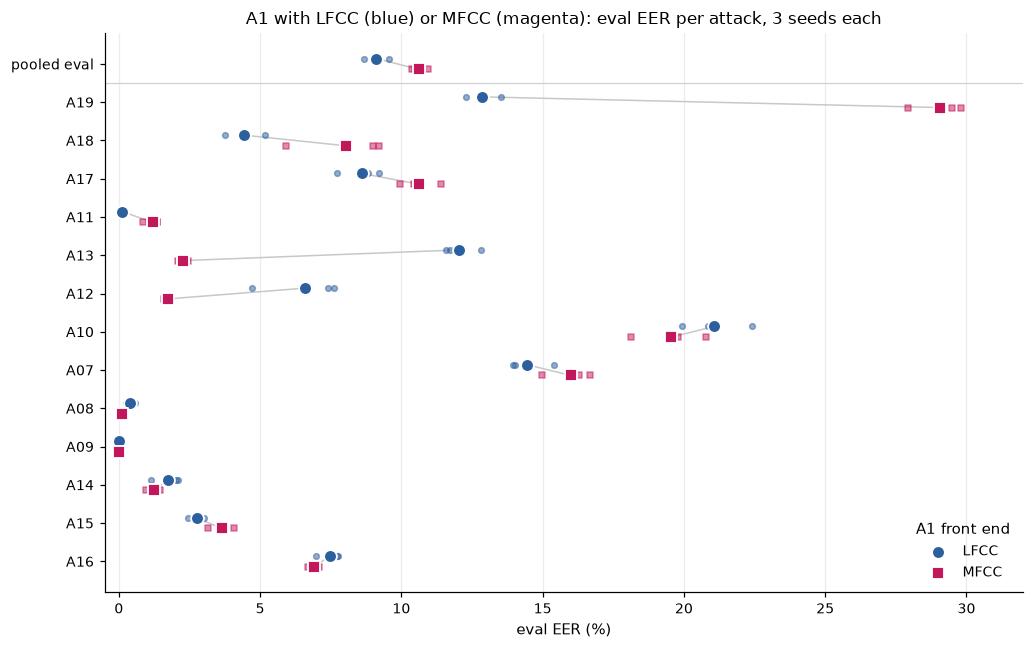

In [14]:
X4 = {
    "LFCC": ["E-20261001-e1-a1-raw", "E-20261004-e2-a1-raw-lfcc-s2337", "E-20261004-e2-a1-raw-lfcc-s3337"],
    "MFCC": ["E-20261004-e2-a1-raw-mfcc-s1337", "E-20261004-e2-a1-raw-mfcc-s2337", "E-20261004-e2-a1-raw-mfcc-s3337"],
}
x4 = {}
for arm, runs in X4.items():
    recs = []
    for r in runs:
        ts = json.load(open(f"runs/{r}/metrics.json"))["testsets"]
        rec = {"pooled": ts["eval"]["eer"], "dev": ts["dev"]["eer"],
               **ts["eval"]["per_attack_eer"]["per_attack"]}
        rec.update({f"dev_{k}": v for k, v in ts["dev"]["per_attack_eer"]["per_attack"].items()})
        recs.append(rec)
    x4[arm] = 100 * pd.DataFrame(recs)
for arm in x4:
    d = x4[arm]
    print(f"{arm}: dev EER {d['dev'].mean():.2f} ± {d['dev'].std():.2f} %, "
          f"eval EER {d['pooled'].mean():.2f} ± {d['pooled'].std():.2f} % (mean ± sd over 3 seeds)")
print(pd.DataFrame({arm: x4[arm].mean() for arm in x4}).round(1)
      .loc[["A10", "A11", "A12", "A13", "A17", "A18", "A19", "dev_A06"]].to_string())

order = ["pooled", "A19", "A18", "A17", "A11", "A13", "A12", "A10",
         "A07", "A08", "A09", "A14", "A15", "A16"]
fig, ax = plt.subplots(figsize=(9.5, 6))
for i, key in enumerate(order):
    for arm, col, mk, dy in [("LFCC", LIN, "o", -0.14), ("MFCC", MEL, "s", 0.14)]:
        v = x4[arm][key]
        ax.scatter(v, np.full(3, i + dy), s=14, color=col, marker=mk, alpha=0.5, zorder=2)
        ax.scatter(v.mean(), i + dy, s=70, color=col, marker=mk, edgecolor="white", lw=1.2,
                   zorder=3, label=arm if i == 0 else None)
    ax.plot([x4["LFCC"][key].mean(), x4["MFCC"][key].mean()], [i - 0.14, i + 0.14],
            color="#c8c8c8", lw=1, zorder=1)
ax.axhline(0.5, color="#d0d0d0", lw=0.8)
ax.set_yticks(range(len(order)), ["pooled eval"] + order[1:])
ax.invert_yaxis()
ax.set_xlabel("eval EER (%)")
ax.set_xlim(-0.5, 32)
ax.grid(axis="x", color="#ececec")
ax.set_axisbelow(True)
ax.legend(loc="lower right", title="A1 front end")
ax.set_title("A1 with LFCC (blue) or MFCC (magenta): eval EER per attack, 3 seeds each")
fig.tight_layout()
save(fig, "ch06_x4_lfcc_vs_mfcc")
plt.show()

## Report figure (ch 07): pool then mix equals mix then pool (toy check on the real head)

**Toy numbers, real code.** Random "hidden states" with A2's shape (13 layers × 199 frames ×
768 dimensions) for 20 made-up clips, and an untrained [`SSLHead`](../src/audio_df/models/ssl_head.py)
with random layer weights. Path 1 mixes the layers frame by frame, then averages over time.
Path 2 averages each layer over time first (what A2 caches), then mixes with
`SSLHead.weighted_sum`. The repo's own test `tests/test_ssl_head.py` checks the same identity.

What to look at: (left) every point lies on the diagonal: the two paths give the same numbers.
(right) put a non-linear step (LayerNorm) on each frame before averaging, and the points leave
the diagonal. That is why A2 applies LayerNorm only after pooling.

max |mix-then-pool − pool-then-mix| = 1.19e-07
max |LayerNorm-per-frame-then-pool − pool-then-LayerNorm| = 3.75


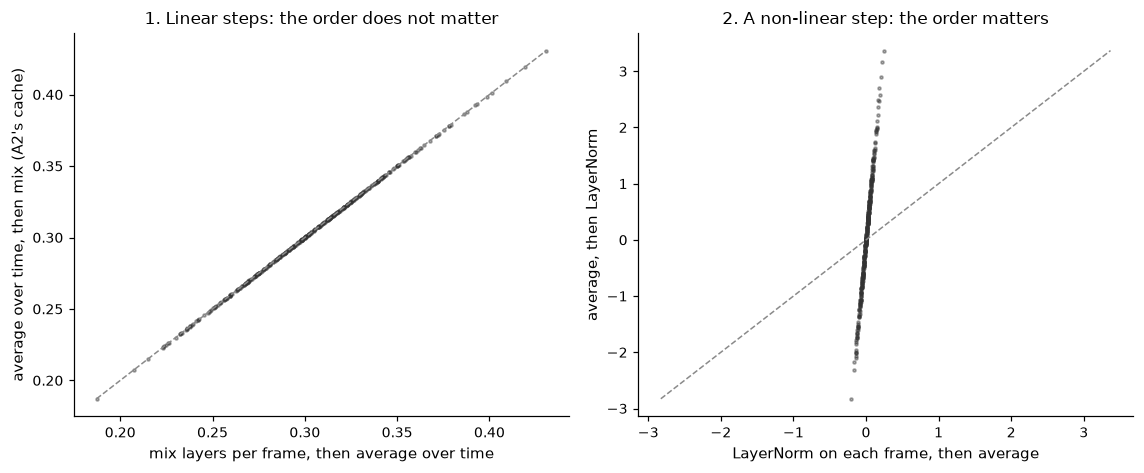

In [15]:
import torch

from audio_df.models.ssl_head import SSLHead

torch.manual_seed(0)
head = SSLHead(n_layers=13, hidden_dim=768)
with torch.no_grad():
    head.layer_logits.copy_(torch.randn(13))
    H = torch.randn(20, 13, 199, 768) * torch.linspace(0.5, 3, 13)[None, :, None, None] + 0.3
    w = head.layer_weights()
    mix_then_pool = torch.einsum("l,bltd->btd", w, H).mean(dim=1)       # frame-level mix, then time mean
    pool_then_mix = head.weighted_sum(H.mean(dim=2))                      # time mean (the cache), then mix
    ln_frames = head.norm(torch.einsum("l,bltd->btd", w, H)).mean(dim=1)  # LayerNorm per frame, then mean
    ln_after = head.norm(pool_then_mix)                                   # what A2 does: LayerNorm after pooling
print(f"max |mix-then-pool − pool-then-mix| = {(mix_then_pool - pool_then_mix).abs().max():.2e}")
print(f"max |LayerNorm-per-frame-then-pool − pool-then-LayerNorm| = {(ln_frames - ln_after).abs().max():.2f}")

fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(10.5, 4.4))
a, b = mix_then_pool.flatten()[::40].numpy(), pool_then_mix.flatten()[::40].numpy()
ax_l.scatter(a, b, s=4, color=INK, alpha=0.4)
lim = [min(a.min(), b.min()), max(a.max(), b.max())]
ax_l.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax_l.set_xlabel("mix layers per frame, then average over time")
ax_l.set_ylabel("average over time, then mix (A2's cache)")
ax_l.set_title("1. Linear steps: the order does not matter")
c, d = ln_frames.flatten()[::40].numpy(), ln_after.flatten()[::40].numpy()
ax_r.scatter(c, d, s=4, color=INK, alpha=0.4)
lim = [min(c.min(), d.min()), max(c.max(), d.max())]
ax_r.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax_r.set_xlabel("LayerNorm on each frame, then average")
ax_r.set_ylabel("average, then LayerNorm")
ax_r.set_title("2. A non-linear step: the order matters")
fig.tight_layout()
save(fig, "ch07_pool_then_mix")
plt.show()

## Report figure (ch 07): which layers A2 weights, and how each layer does on its own

**Source:** `runs/E-20261001-e1-a2-raw/layer_weights.json` (the E1 head's 13 learned
weights) and `runs/E-20261004-e2-a2-raw-layers/summary.csv` (the E2 single-layer
runs: one head trained on each single layer, scored with its own dev threshold). Both committed.

What to look at: (left) the learned weights are all close to the even share 1/13 (dotted
line), tilted a little toward the bottom layers (measured 0.094-0.099 for layers 0, 2 and 3,
0.061-0.069 for layers 8-12; max/min 1.63). (right) each layer alone: the solid line
(eval, raw) is low for layers 1–7, rising toward the top; the dashed line (eval with silence
trimmed) is lowest in the middle, layers 3–5 (10.06-13.72 %); the dotted line (In-the-Wild) is fairly flat. The
grey band marks the full head over 3 seeds (mean ± sd) on each test: 1.32 ± 0.23 % eval,
13.69 ± 0.62 % trimmed eval, 14.03 ± 0.49 % In-the-Wild.

learned weights: [0.094, 0.081, 0.095, 0.099, 0.08, 0.081, 0.074, 0.066, 0.061, 0.066, 0.068, 0.067, 0.069] max/min = 1.63
         eval_eer  eval_trimmed_eer  itw_eer
variant                                     
layer00     10.99             38.93    13.82
layer01      2.57             23.29    14.79
layer02      2.11             17.19    19.17
layer03      1.50             13.72    19.11
layer04      1.67             13.31    17.78
layer05      1.41             10.06    15.19
layer06      2.83             15.63    14.92
layer07      2.18             24.08    17.97
layer08      3.72             25.44    19.33
layer09      3.80             22.05    19.62
layer10      3.87             20.76    16.45
layer11      4.47             20.99    15.24
layer12      6.04             23.21    16.52
full head mean ± sd: {'eval_eer': '1.32 ± 0.23', 'eval_trimmed_eer': '13.69 ± 0.62', 'itw_eer': '14.03 ± 0.49'}


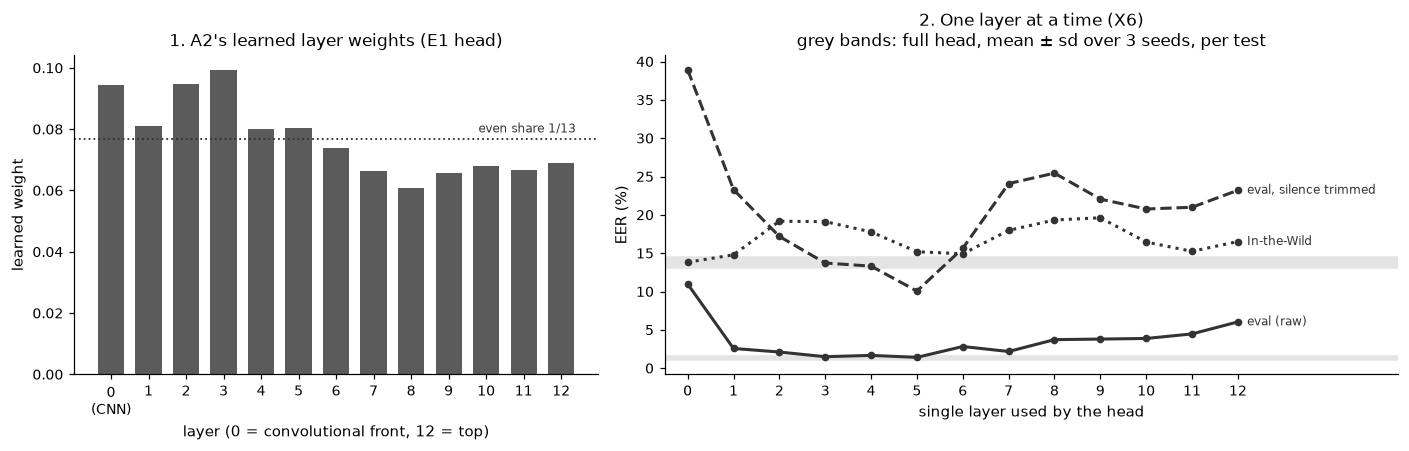

In [16]:
lw_ = np.array(json.load(open("runs/E-20261001-e1-a2-raw/layer_weights.json")))
x6 = pd.read_csv("runs/E-20261004-e2-a2-raw-layers/summary.csv").set_index("variant")
single = x6.loc[[f"layer{i:02d}" for i in range(13)]] * 100
full = x6.loc[["full_seed1337", "full_seed2337", "full_seed3337"]] * 100
print("learned weights:", np.round(lw_, 3).tolist(), f"max/min = {lw_.max() / lw_.min():.2f}")
print(single[["eval_eer", "eval_trimmed_eer", "itw_eer"]].round(2).to_string())
print("full head mean ± sd:", {c: f"{full[c].mean():.2f} ± {full[c].std():.2f}"
                               for c in ["eval_eer", "eval_trimmed_eer", "itw_eer"]})

fig, (ax_w, ax_e) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax_w.bar(range(13), lw_, color="#5b5b5b", width=0.7)
ax_w.axhline(1 / 13, color=INK, ls=":", lw=1.2)
ax_w.text(12.4, 1 / 13 + 0.002, "even share 1/13", ha="right", fontsize=8, color=INK)
ax_w.set_xticks(range(13), ["0\n(CNN)"] + [str(i) for i in range(1, 13)])
ax_w.set_xlabel("layer (0 = convolutional front, 12 = top)")
ax_w.set_ylabel("learned weight")
ax_w.set_title("1. A2's learned layer weights (E1 head)")

L = np.arange(13)
for colname, ls, lab in [("eval_eer", "-", "eval (raw)"), ("eval_trimmed_eer", "--", "eval, silence trimmed"),
                         ("itw_eer", ":", "In-the-Wild")]:
    m, s = full[colname].mean(), full[colname].std()
    ax_e.axhspan(m - s, m + s, color="#e4e4e4", zorder=0)
    ax_e.plot(L, single[colname], ls=ls, color=INK, lw=2, marker="o", ms=4, zorder=2)
    ax_e.annotate(lab, (12, single[colname].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                  fontsize=8, color=INK, va="center")
ax_e.set_xticks(L)
ax_e.set_xlim(-0.5, 15.5)
ax_e.set_xlabel("single layer used by the head")
ax_e.set_ylabel("EER (%)")
ax_e.set_title("2. One layer at a time (X6)\ngrey bands: full head, mean ± sd over 3 seeds, per test")
fig.tight_layout()
save(fig, "ch07_layer_weights_x6")
plt.show()

## Report figure (ch 07): which layer catches which attack (single-layer heatmap)

**Source:** `runs/E-20261004-e2-a2-raw-layers/per_attack_heatmap.png`, committed by the
E2 single-layer run and displayed here unchanged. Columns: the full head (seed 1337) and the 13 single-layer
heads; rows: eval attacks; numbers: EER in %, rounded. Left: raw eval audio; right: silence
trimmed.

What to look at: A18 and A19 (bottom two rows, voice conversion of real recordings) are dark at
layers 1–5 and get brighter toward layer 12. A17 is darkest in the middle layers (4–6). Layer 0
is poor for all three, and A10 (row 4) is caught better by layers 7 and above.

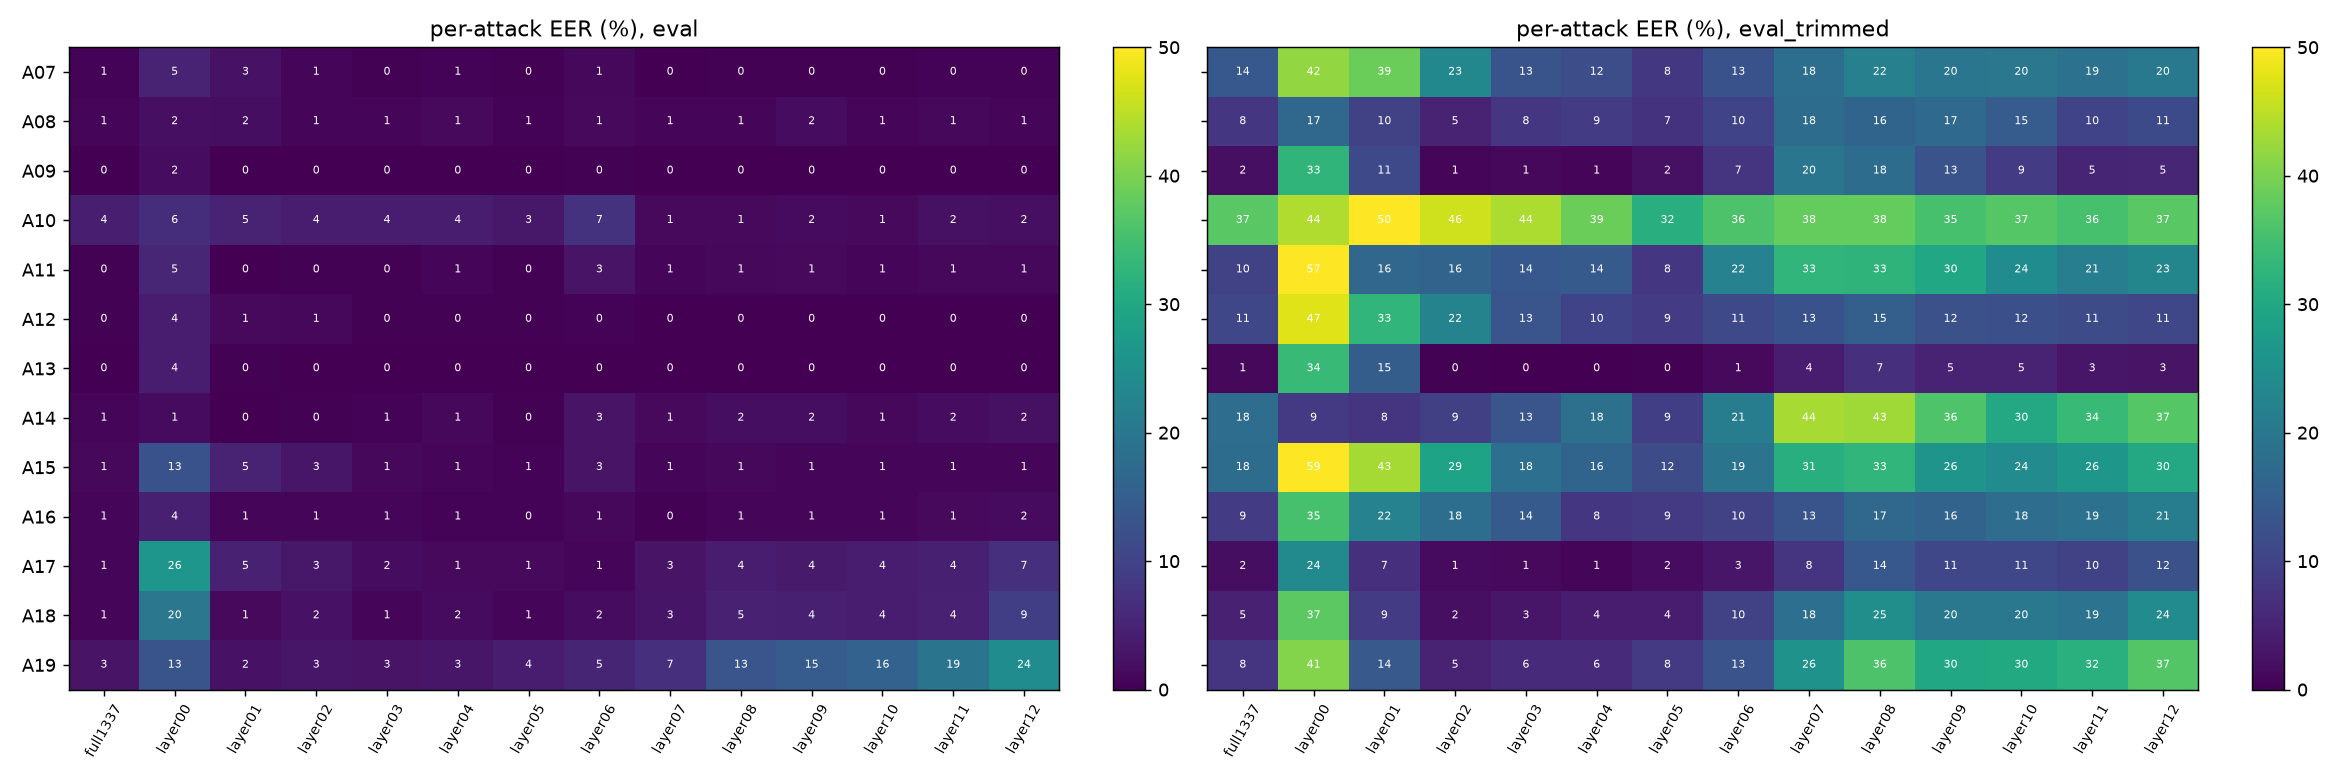

     layer01  layer07  layer12
A10      4.8      1.2      2.1
A17      4.5      2.5      6.7
A18      1.3      2.9      9.3
A19      2.5      6.8     24.3


In [17]:
from IPython.display import Image, display

import shutil

display(Image(filename="runs/E-20261004-e2-a2-raw-layers/per_attack_heatmap.png", width=1100))
shutil.copy("runs/E-20261004-e2-a2-raw-layers/per_attack_heatmap.png", IMG_DIR / "ch07_x6_heatmap.png")
pa6 = pd.read_csv("runs/E-20261004-e2-a2-raw-layers/per_attack_eval.csv", index_col=0) * 100
print(pa6.loc[["A10", "A17", "A18", "A19"], ["layer01", "layer07", "layer12"]].round(1).to_string())

## Report figure (ch 08): A2's scores before and after trimming the silence

**Source:** committed eval scores of A2 on raw audio (`E-20261001-e1-a2-raw`) and on the same
clips with leading and trailing silence trimmed (`E-20261001-e1-a2-trimmed`, same trained head),
plus the raw dev threshold. The medians and rates are recomputed from those files.

What to look at: the green pile (real clips) jumps left by about 19 points when silence is
removed, across the dashed threshold; the orange pile (fakes) barely moves.

A2 eval raw     : median real +14.90, median fake -12.83, real rejected at the raw dev threshold 0.2%, fake accepted 4.3%
A2 eval trimmed : median real -4.18, median fake -15.60, real rejected at the raw dev threshold 62.1%, fake accepted 1.6%


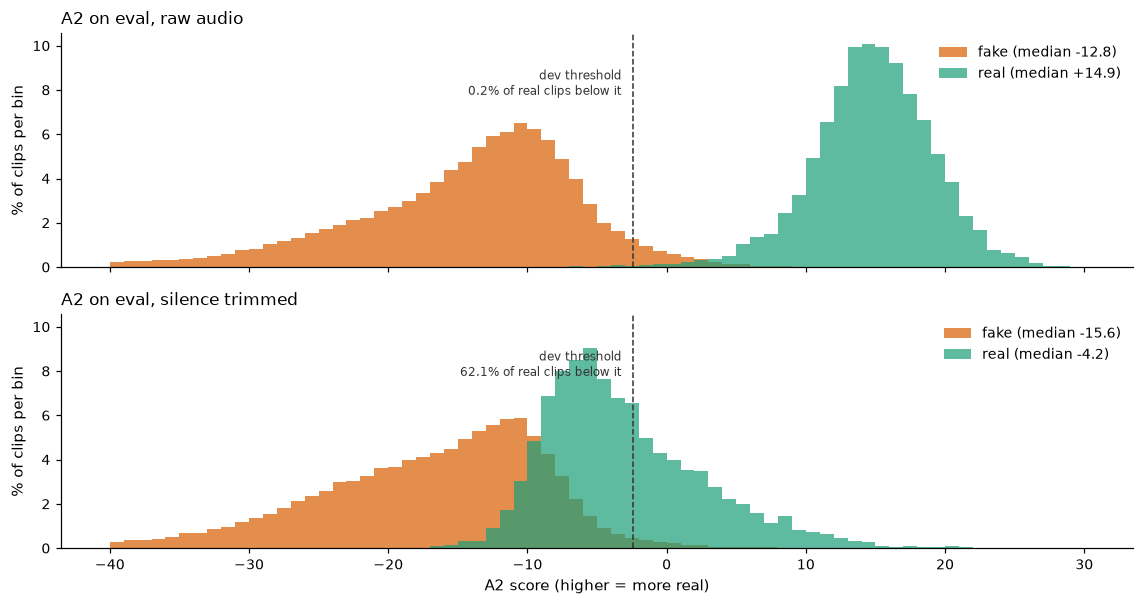

In [18]:
def load_pair(sysname):
    raw = pd.read_csv(f"runs/E-20261001-e1-{sysname}-raw/scores/eval.csv")
    trim = pd.read_csv(f"runs/E-20261001-e1-{sysname}-trimmed/scores/eval.csv")
    thr = json.load(open(f"runs/E-20261001-e1-{sysname}-raw/metrics.json"))["threshold_source"]["value"]
    return raw, trim, thr


a2_raw, a2_trim, a2_thr = load_pair("a2")
stats8 = {}
for name, d in [("raw", a2_raw), ("trimmed", a2_trim)]:
    b, s = d[d.label == "bonafide"].score, d[d.label == "spoof"].score
    stats8[name] = (b.median(), s.median(), (b <= a2_thr).mean(), (s > a2_thr).mean())
    print(f"A2 eval {name:8s}: median real {b.median():+.2f}, median fake {s.median():+.2f}, "
          f"real rejected at the raw dev threshold {(b <= a2_thr).mean():.1%}, "
          f"fake accepted {(s > a2_thr).mean():.1%}")

bins = np.linspace(-40, 30, 71)
fig, axes = plt.subplots(2, 1, figsize=(10.5, 5.6), sharex=True, sharey=True)
for ax, (name, d) in zip(axes, [("raw audio", a2_raw), ("silence trimmed", a2_trim)]):
    for lab, col in [("spoof", SPOOF), ("bonafide", BONA)]:
        v = d[d.label == lab].score
        ax.hist(v, bins=bins, weights=np.full(len(v), 100 / len(v)), color=col, alpha=0.7,
                label=("real" if lab == "bonafide" else "fake") + f" (median {v.median():+.1f})")
    ax.axvline(a2_thr, color=INK, ls="--", lw=1)
    rej = (d[d.label == "bonafide"].score <= a2_thr).mean()
    ax.text(a2_thr - 0.8, ax.get_ylim()[1] * 0.85, f"dev threshold\n{rej:.1%} of real clips below it",
            ha="right", va="top", fontsize=8, color=INK)
    ax.set_title(f"A2 on eval, {name}", loc="left")
    ax.set_ylabel("% of clips per bin")
    ax.legend(loc="upper right")
axes[1].set_xlabel("A2 score (higher = more real)")
fig.tight_layout()
save(fig, "ch08_a2_raw_vs_trimmed_scores")
plt.show()

## Report figure (ch 08): every attack's EER, raw against trimmed, for A1 and A2

**Source:** per-attack EER in the committed `metrics.json` of `E-20261001-e1-{a1,a2}-{raw,trimmed}`.
Each row is one eval attack; the filled dot is raw audio, the open dot trimmed, joined by a line.
Both panels share one x-axis.

What to look at: for A2 (right) nearly every attack gets worse, A10 most (2.0 → 39.5 %), while
A13 and A17 barely move. For A1 (left) most attacks get worse, but A17 and A19 get *better*.

A1           A07  A08  A09   A10  A11   A12   A13  A14  A15   A16  A17   A18   A19
raw      15.4  0.3  0.0  22.4  0.1   7.6  12.8  1.1  2.8   7.8  8.8   4.4  12.7
trimmed  27.3  0.7  0.2  36.7  1.5  36.0  24.9  3.7  6.1  31.5  3.6  20.0  11.2
A2           A07  A08  A09   A10  A11   A12  A13   A14   A15  A16  A17  A18  A19
raw       0.2  0.6  0.0   2.0  0.2   0.1  0.0   0.4   0.5  0.4  0.9  0.9  1.9
trimmed  13.5  7.1  1.3  39.5  9.5  10.8  0.7  17.8  17.9  9.3  1.8  4.6  7.4


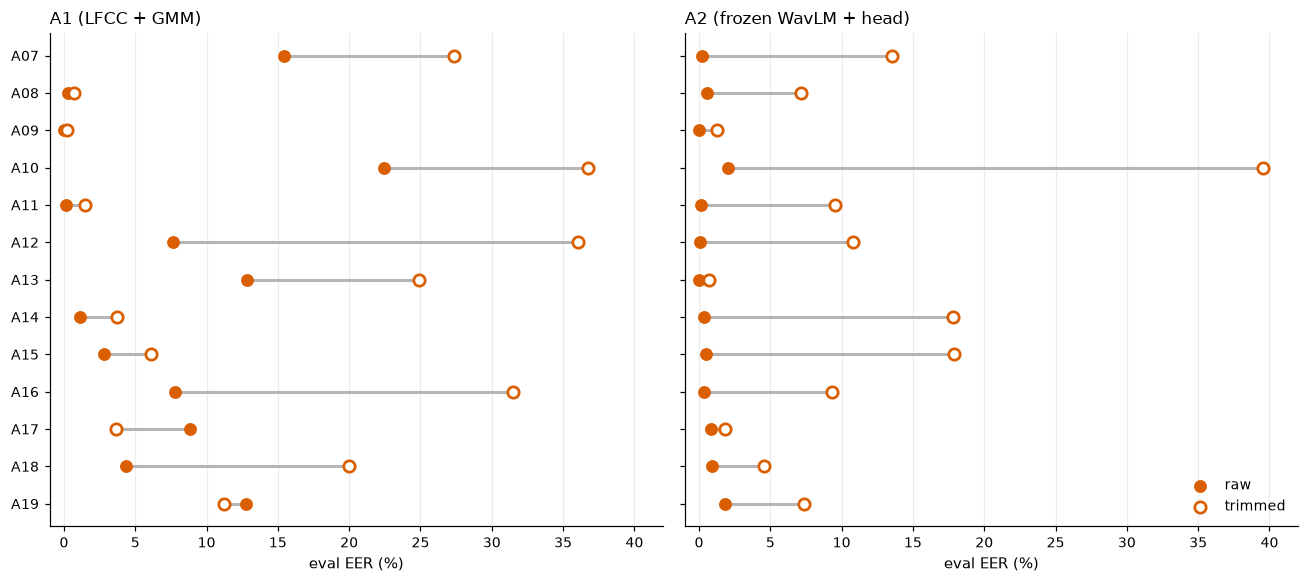

In [19]:
def per_attack(exp):
    return pd.Series(json.load(open(f"runs/{exp}/metrics.json"))["testsets"]["eval"]
                     ["per_attack_eer"]["per_attack"]) * 100


atts = [f"A{i:02d}" for i in range(7, 20)]
pa8 = {s: pd.DataFrame({"raw": per_attack(f"E-20261001-e1-{s}-raw"),
                        "trimmed": per_attack(f"E-20261001-e1-{s}-trimmed")}).loc[atts]
       for s in ["a1", "a2"]}
for s in pa8:
    print(s.upper(), pa8[s].round(1).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
for ax, s, title in [(axes[0], "a1", "A1 (LFCC + GMM)"), (axes[1], "a2", "A2 (frozen WavLM + head)")]:
    d = pa8[s]
    for i, a in enumerate(atts):
        r, t = d.loc[a, "raw"], d.loc[a, "trimmed"]
        ax.plot([r, t], [i, i], color="#b5b5b5", lw=2, zorder=1)
        ax.scatter(r, i, s=55, color=SPOOF, zorder=3, label="raw" if i == 0 else None)
        ax.scatter(t, i, s=55, facecolor="white", edgecolor=SPOOF, lw=1.8, zorder=3,
                   label="trimmed" if i == 0 else None)
    ax.set_title(title, loc="left")
    ax.set_xlabel("eval EER (%)")
    ax.grid(axis="x", color="#ececec")
    ax.set_axisbelow(True)
    ax.set_xlim(-1, 42)
axes[0].set_yticks(range(len(atts)), atts)
axes[0].invert_yaxis()
axes[1].legend(loc="lower right")
fig.tight_layout()
save(fig, "ch08_per_attack_raw_vs_trimmed")
plt.show()

## Report figure (ch 08): how A1's median score moves when silence is trimmed, per group

**Source:** the committed A1 eval score files, raw and trimmed, joined on clip id; each bar is
the trimmed median minus the raw median for that group (recomputed here). Positive =
the group looks *more real* after trimming.

What to look at: real clips (green) drop a little (−0.31). Most attacks stay put. A09, A12 and
A16 rise; A17 and A19 fall; A18 rises slightly, which no simple explanation predicts.

        raw  trim  shift
group                   
A07    0.71  0.71  -0.00
A08   -1.65 -1.83  -0.19
A09   -8.38 -4.18   4.20
A10    0.93  0.92  -0.01
A11   -1.19 -0.94   0.25
A12   -0.70  0.92   1.62
A13    0.53  0.61   0.08
A14   -0.57 -0.68  -0.11
A15   -0.03 -0.17  -0.14
A16   -0.71  0.78   1.49
A17    0.33 -0.60  -0.92
A18    0.43  0.59   0.15
A19    0.68  0.17  -0.52
real   1.50  1.19  -0.31


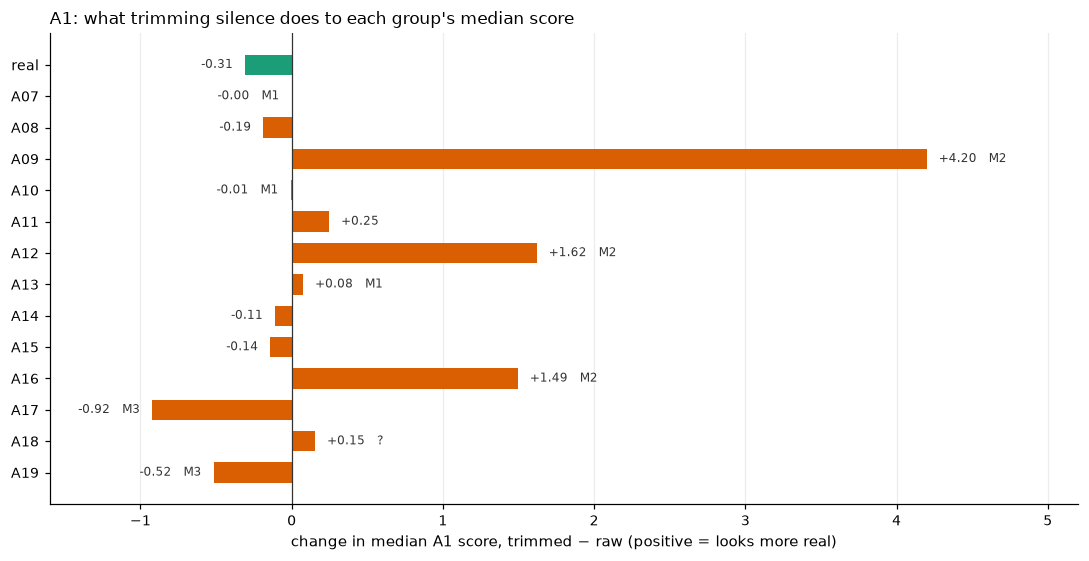

In [20]:
a1_raw, a1_trim, a1_thr = load_pair("a1")
j = a1_raw.merge(a1_trim, on=["clip_id", "label", "attack_id"], suffixes=("_raw", "_trim"))
assert len(j) == len(a1_raw) == len(a1_trim)
j["group"] = np.where(j.label == "bonafide", "real", j.attack_id)
g = j.groupby("group").agg(raw=("score_raw", "median"), trim=("score_trim", "median"))
g["shift"] = g.trim - g.raw
print(g.round(2).to_string())

order = ["real"] + atts
mech = {"A07": "M1", "A10": "M1", "A13": "M1", "A09": "M2", "A12": "M2", "A16": "M2",
        "A17": "M3", "A19": "M3", "A18": "?"}
fig, ax = plt.subplots(figsize=(10, 5.2))
vals = g.loc[order, "shift"]
ax.barh(range(len(order)), vals, color=[BONA] + [SPOOF] * len(atts), height=0.65)
for i, a in enumerate(order):
    v = vals.iloc[i]
    txt = f"{v:+.2f}" + (f"   {mech[a]}" if a in mech else "")
    ax.text(v + (0.08 if v >= 0 else -0.08), i, txt, va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color=INK)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlim(-1.6, 5.2)
ax.set_xlabel("change in median A1 score, trimmed − raw (positive = looks more real)")
ax.set_title("A1: what trimming silence does to each group's median score", loc="left")
ax.grid(axis="x", color="#ececec")
ax.set_axisbelow(True)
fig.tight_layout()
save(fig, "ch08_a1_median_shift")
plt.show()

## Report figure (ch 09): A1 and A2 on In-the-Wild, with the threshold chosen at home

**Source:** committed In-the-Wild scores of `E-20261001-e3-a1-raw` and `E-20261001-e3-a2-raw`
(raw audio), each system's raw dev threshold from its E1 run, and, as a grey outline for
reference, the same system's real eval clips, which come from the Voice Cloning Toolkit
(VCTK) corpus. Rates are recomputed here.

What to look at: for A2 (bottom) the two In-the-Wild piles are still well apart, but the real
pile has moved left of where VCTK real clips sat, straddling the dashed threshold. For A1 (top)
the In-the-Wild piles sit on top of each other, fakes slightly to the *right*. A1's panel is
cut at −3, which hides part of the fakes' long left tail.

A1 ITW: EER 58.04 %, AUC 0.398, medians real +0.44 fake +0.69; at the dev threshold +0.687: real rejected 71.8%, fake accepted 50.0%; VCTK eval real median +1.50
A2 ITW: EER 14.70 %, AUC 0.934, medians real -2.19 fake -16.91; at the dev threshold -2.425: real rejected 48.9%, fake accepted 1.6%; VCTK eval real median +14.90


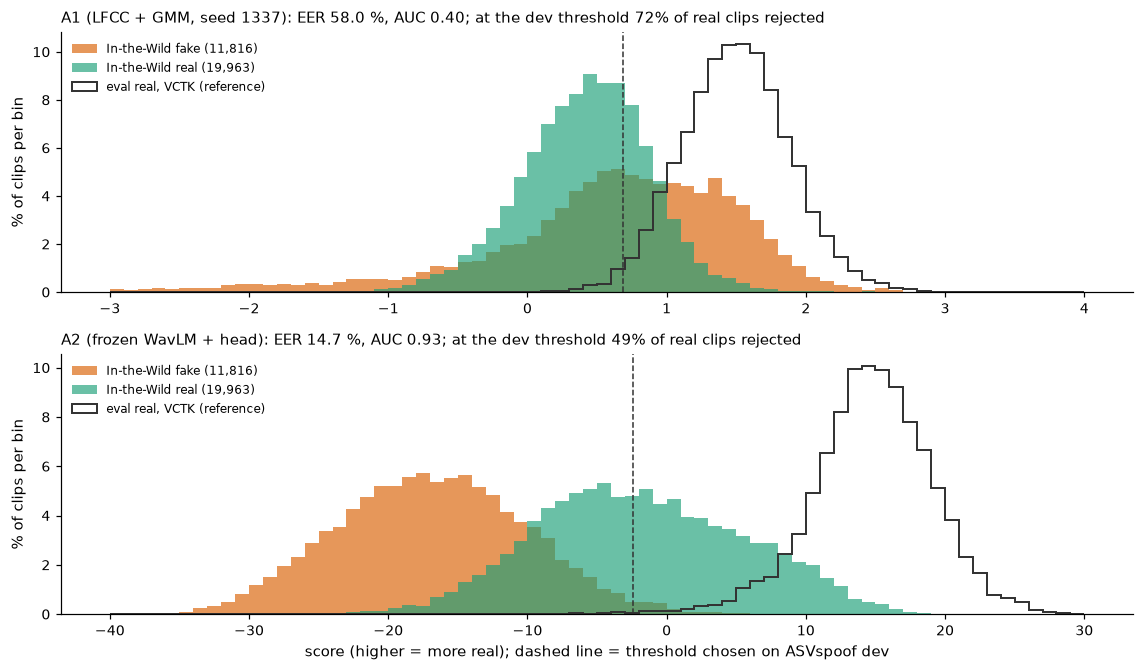

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(10.5, 6.2))
for ax, s, title, rng in [(axes[0], "a1", "A1 (LFCC + GMM, seed 1337)", (-3, 4)),
                          (axes[1], "a2", "A2 (frozen WavLM + head)", (-40, 30))]:
    itw = pd.read_csv(f"runs/E-20261001-e3-{s}-raw/scores/itw.csv")
    ev = pd.read_csv(f"runs/E-20261001-e1-{s}-raw/scores/eval.csv")
    thr = json.load(open(f"runs/E-20261001-e3-{s}-raw/metrics.json"))["threshold_source"]["value"]
    m = json.load(open(f"runs/E-20261001-e3-{s}-raw/metrics.json"))["testsets"]["itw"]
    bins = np.linspace(*rng, 71)
    for lab, col, name in [("spoof", SPOOF, "In-the-Wild fake"), ("bonafide", BONA, "In-the-Wild real")]:
        v = itw[itw.label == lab].score
        ax.hist(v, bins=bins, weights=np.full(len(v), 100 / len(v)), color=col, alpha=0.65,
                label=f"{name} ({len(v):,})")
    vb = ev[ev.label == "bonafide"].score
    ax.hist(vb, bins=bins, weights=np.full(len(vb), 100 / len(vb)), histtype="step", color=INK,
            lw=1.3, label="eval real, VCTK (reference)")
    ax.axvline(thr, color=INK, ls="--", lw=1)
    b, f = itw[itw.label == "bonafide"].score, itw[itw.label == "spoof"].score
    print(f"{s.upper()} ITW: EER {100 * m['eer']:.2f} %, AUC {m['roc_auc']:.3f}, medians real {b.median():+.2f} "
          f"fake {f.median():+.2f}; at the dev threshold {thr:+.3f}: real rejected {(b <= thr).mean():.1%}, "
          f"fake accepted {(f > thr).mean():.1%}; VCTK eval real median {vb.median():+.2f}")
    ax.set_title(f"{title}: EER {100 * m['eer']:.1f} %, AUC {m['roc_auc']:.2f}; "
                 f"at the dev threshold {(b <= thr).mean():.0%} of real clips rejected", loc="left", fontsize=10)
    ax.set_ylabel("% of clips per bin")
    ax.legend(loc="upper left", fontsize=8)
axes[1].set_xlabel("score (higher = more real); dashed line = threshold chosen on ASVspoof dev")
fig.tight_layout()
save(fig, "ch09_itw_scores_threshold")
plt.show()

## Report figure (ch 09): LFCC against MFCC, at home and away (E2 front-end runs, 3 seeds each)

**Source:** the six E2 front-end `metrics.json` files (LFCC seeds 1337, 2337, 3337; MFCC seeds
1337, 2337, 3337): eval EER and In-the-Wild EER per seed (the seed-1337 LFCC model's In-the-Wild
score is in its E3 run, `E-20261001-e3-a1-raw`). Each line is one trained model.

What to look at: on the left (ASVspoof eval) the blue LFCC lines start lower than the magenta
MFCC lines. On the right (In-the-Wild) the order flips: MFCC lands near 31–34 % and its three
seeds agree; LFCC lands near or past 50 % and its three seeds disagree.

 arm                             run   eval    itw  itw_auc
LFCC            E-20261001-e1-a1-raw  9.557 58.041    0.398
LFCC E-20261004-e2-a1-raw-lfcc-s2337  8.674 45.955    0.560
LFCC E-20261004-e2-a1-raw-lfcc-s3337  9.122 58.582    0.381
MFCC E-20261004-e2-a1-raw-mfcc-s1337 10.947 33.151    0.713
MFCC E-20261004-e2-a1-raw-mfcc-s2337 10.391 30.737    0.764
MFCC E-20261004-e2-a1-raw-mfcc-s3337 10.496 33.726    0.713
       eval          itw       itw_auc      
       mean   std   mean   std    mean   std
arm                                         
LFCC   9.12  0.44  54.19  7.14    0.45  0.10
MFCC  10.61  0.30  32.54  1.59    0.73  0.03


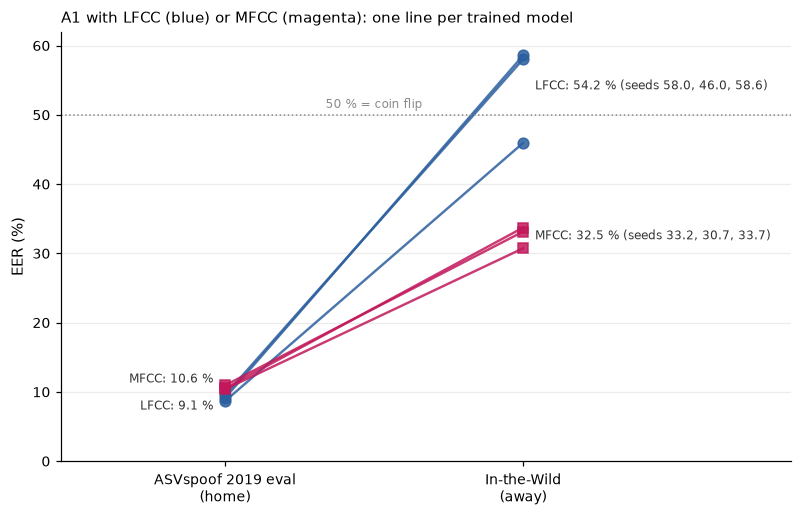

In [22]:
pts = []
for arm, runs in X4.items():
    for r in runs:
        ts = json.load(open(f"runs/{r}/metrics.json"))["testsets"]
        # The E1 LFCC run (seed 1337) was scored on In-the-Wild in its own E3 run folder.
        itw_run = "E-20261001-e3-a1-raw" if r == "E-20261001-e1-a1-raw" else r
        ti = json.load(open(f"runs/{itw_run}/metrics.json"))["testsets"]["itw"]
        pts.append({"arm": arm, "run": r, "eval": 100 * ts["eval"]["eer"], "itw": 100 * ti["eer"],
                    "itw_auc": ti["roc_auc"]})
pts = pd.DataFrame(pts)
print(pts.round(3).to_string(index=False))
print(pts.groupby("arm")[["eval", "itw", "itw_auc"]].agg(["mean", "std"]).round(2).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for _, r in pts.iterrows():
    col, mk = (LIN, "o") if r.arm == "LFCC" else (MEL, "s")
    ax.plot([0, 1], [r["eval"], r["itw"]], color=col, lw=1.6, marker=mk, ms=7, alpha=0.85)
for arm, col in [("LFCC", LIN), ("MFCC", MEL)]:
    d = pts[pts.arm == arm]
    ax.text(1.04, d["itw"].mean(), f"{arm}: {d['itw'].mean():.1f} % (seeds {', '.join(f'{v:.1f}' for v in d['itw'])})",
            va="center", fontsize=8, color=INK)
    ax.text(-0.04, d["eval"].mean() + (1.2 if arm == "MFCC" else -1.2), f"{arm}: {d['eval'].mean():.1f} %",
            va="center", ha="right", fontsize=8, color=INK)
ax.axhline(50, color=MUTED, ls=":", lw=1)
ax.text(0.5, 51, "50 % = coin flip", ha="center", fontsize=8, color=MUTED)
ax.set_xticks([0, 1], ["ASVspoof 2019 eval\n(home)", "In-the-Wild\n(away)"])
ax.set_xlim(-0.55, 1.9)
ax.set_ylim(0, 62)
ax.set_ylabel("EER (%)")
ax.set_title("A1 with LFCC (blue) or MFCC (magenta): one line per trained model", loc="left", fontsize=10)
ax.grid(axis="y", color="#ececec")
ax.set_axisbelow(True)
fig.tight_layout()
save(fig, "ch09_x4_home_vs_away")
plt.show()

## Report figure (ch 10): A3 margin check

**Recomputed** from committed files: A2's dev and In-the-Wild scores
(`E-20261001-e1-a2-raw`, `E-20261001-e3-a2-raw`), A2's dev threshold, and the level margins in
`configs/a3_jev.yaml`. No plot: the cell prints how many clips would fall in A3's "uncertain" band
and how many real In-the-Wild clips the configured levels would call "strongly spoof".

In [23]:
a3_cfg = yaml.safe_load(open("configs/a3_jev.yaml"))
m1, m2 = a3_cfg["thresholds"]["detector"]["margins"]
thr_a2 = json.load(open("runs/E-20261001-e1-a2-raw/metrics.json"))["threshold_source"]["value"]
dev_a2 = pd.read_csv("runs/E-20261001-e1-a2-raw/scores/dev.csv")
itw_a2 = pd.read_csv("runs/E-20261001-e3-a2-raw/scores/itw.csv")
d_dev = dev_a2.score - thr_a2
d_itw_real = itw_a2[itw_a2.label == "bonafide"].score - thr_a2
print(f"configured margins: m1 = {m1}, m2 = {m2}; A2 dev threshold = {thr_a2:.4f}")
print(f"A2 dev scores range from {dev_a2.score.min():.1f} to {dev_a2.score.max():.1f}")
print(f"dev clips within ±{m1} of the threshold ('borderline'): {(d_dev.abs() <= m1).mean():.2%}")
print(f"dev clips within ±{m2} of the threshold (not 'strongly' either way): {(d_dev.abs() <= m2).mean():.2%}")
print(f"In-the-Wild real clips at or below threshold − {m2} ('strongly spoof'): {(d_itw_real <= -m2).mean():.1%}")

configured margins: m1 = 0.05, m2 = 0.2; A2 dev threshold = -2.4253
A2 dev scores range from -46.4 to 27.6
dev clips within ±0.05 of the threshold ('borderline'): 0.02%
dev clips within ±0.2 of the threshold (not 'strongly' either way): 0.10%
In-the-Wild real clips at or below threshold − 0.2 ('strongly spoof'): 47.9%
